In [346]:
import pandas as pd
import numpy as np
import sys
import os
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import mahalanobis
from scipy.linalg import pinv
from scipy.stats import pearsonr
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.covariance import LedoitWolf


sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [347]:
inputs_dirs = "../1_inputs/sqY2H"
output_dirs = "../3_outputs/sqY2H"
meta_outputs = '../../../1_allele_collection/3_outputs'

# Variables

In [348]:
scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']
max_score = 750
aa_id = 0
rrs_id = 999999.0
size_value = 1150
size_filter = False
papilation_filter = False

# Data loading

Number of rows before replacing outliers: 306431
Number of values replaced with NaN: 3057
Percentage of values replaced: 1.00%
Number of rows after replacing outliers: 306431


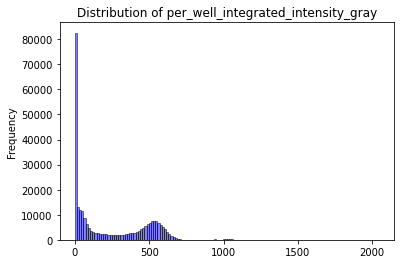

In [349]:
# Load the data from the automated scoring pipeline
auto_df = pd.read_csv(f"{inputs_dirs}/sqY2H_manual_automated_annotated_scores_size.csv")

# both ad_orf_id and db_orf_id must have values (otherwise they are empty wells)
auto_df = auto_df[
    (~auto_df.ad_orf_id.isin(['nan', 'None'])) &
    (~auto_df.db_orf_id.isin(['nan', 'None']))
]

# Remove rows where manual_score_growth is NaN because those wells are flagged as contamination

# do not drop but replace the automatic scores by NA or just add a column for the failling of the manual annotation
# auto_df.dropna(subset=['manual_score_growth'], inplace=True)
auto_df['contamination'] = auto_df['manual_score_growth'].isna()
auto_df

# try to replace per_well_integrated_intensity_gray with NaN if manual_score_growth is NaN
auto_df.loc[auto_df['manual_score_growth'].isna(), 'per_well_integrated_intensity_gray'] = np.nan

# plotting the distribution of per_well_integrated_intensity_gray
auto_df.per_well_integrated_intensity_gray.plot(kind='hist', bins=140, alpha=0.5, color='blue', edgecolor='black', title="Distribution of per_well_integrated_intensity_gray")

# replacing upper bound outliers with NaN because they're caused by misaligned wells
auto_full = auto_df.copy()



# Counting the number of values replaced with NaN
outlier_mask = auto_df.per_well_integrated_intensity_gray >= 750
num_outliers = outlier_mask.sum()

print(f"Number of rows before replacing outliers: {len(auto_df)}")
auto_df.loc[outlier_mask, 'per_well_integrated_intensity_gray'] = np.nan
print(f"Number of values replaced with NaN: {num_outliers}")
print(f"Percentage of values replaced: {(num_outliers / len(auto_df)) * 100:.2f}%")
print(f"Number of rows after replacing outliers: {len(auto_df)}")

In [350]:
size_mask = auto_df.total_colony_area >= size_value
num_size_outliers = size_mask.sum()
print(f"Number of rows before replacing size outliers: {len(auto_df)}")
print(f"Number of values with total_colony_area >= {size_value}: {num_size_outliers}")
print(f"Percentage of values with total_colony_area >= {size_value}: {(num_size_outliers / len(auto_df)) * 100:.2f}%")
if size_filter:
    auto_df.loc[size_mask, 'per_well_integrated_intensity_gray'] = np.nan
auto_df_filtered = auto_df.dropna(subset=['per_well_integrated_intensity_gray'])
print(f"Number of rows after replacing size outliers: {len(auto_df_filtered)}")

Number of rows before replacing size outliers: 306431
Number of values with total_colony_area >= 1150: 5093
Percentage of values with total_colony_area >= 1150: 1.66%
Number of rows after replacing size outliers: 278244


In [351]:
auto_df_filtered['Children_reExpandedColonies_Count'].value_counts(normalize=True) * 100

Children_reExpandedColonies_Count
1     58.015986
0     23.716594
2      9.647288
3      4.252023
4      2.170397
5      1.171993
6      0.594802
7      0.266313
8      0.106381
9      0.039534
10     0.014016
11     0.002875
13     0.001078
12     0.000359
15     0.000359
Name: proportion, dtype: float64

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


95th percentile of MADs: 179.3738266281783


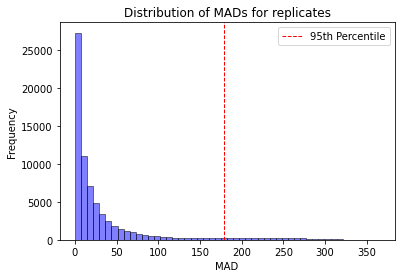

Number of replicates with MAD below 95th percentile: 66674
Total number of replicates: 71706


In [352]:
mads = []

mads_tuples = []

for group, df in auto_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
    scores = df['per_well_integrated_intensity_gray'].dropna().values
    scores_nan = df['per_well_integrated_intensity_gray'].values
    # compute the Median absolute deviation (MAD) of the scores
    median = np.median(scores)
    mean = np.mean(scores)
    mad = np.median(np.abs(scores - median))
    mads.append(mad)
    mads_tuples.append((mad, scores, median, mean))
    # if np.isnan(mad):
        # print(f"Group {group} has NaN MAD with scores: {scores_nan}")

# 95th percentile of MADs, dropping NaNs first
mads_no_nan = [mad for mad in mads if not np.isnan(mad)]
mad_95 = np.percentile(mads_no_nan, 95)
print(f"95th percentile of MADs: {mad_95}")

plt.hist(mads, bins=50, alpha=0.5, color='blue', edgecolor='black')
plt.axvline(mad_95, color='red', linestyle='dashed', linewidth=1, label='95th Percentile')
plt.xlabel('MAD')
plt.ylabel('Frequency')
plt.title('Distribution of MADs for replicates')
plt.legend()
plt.show()

# count the number of replicates with MAD below the 95th percentile
num_below_95 = sum(mad < mad_95 for mad in mads)
print(f"Number of replicates with MAD below 95th percentile: {num_below_95}")
print(f"Total number of replicates: {len(mads)}")


Number of groups with consensus score: 66018
Number of groups without consensus score: 5688
Total number of groups: 71706
Percentage of groups with consensus score: 92.07%


<Axes: ylabel='Frequency'>

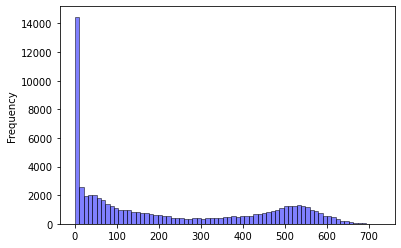

In [353]:
# Compute consensus scores for replicates with MAD below the 95th percentile by taking the mean of the scores and adding it to a new column 'consensus_score'
auto_df['consensus_score'] = np.nan
auto_df['consensus_score'] = auto_df.groupby(
    ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']
)['per_well_integrated_intensity_gray'].transform(
    lambda x: np.mean(x.dropna()) if len(x.dropna()) > 2 and np.median(np.abs(x.dropna() - np.median(x.dropna()))) < mad_95 else np.nan
)

auto_df_full = auto_df.copy()

# Remove duplicate rows - keep only one row per group after consensus calculation
auto_df = auto_df.drop_duplicates(subset=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']).reset_index(drop=True)



# Count groups with and without consensus scores more efficiently
consensus_summary = auto_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'])['consensus_score'].first().notna()
consensus_count = consensus_summary.sum()
no_consensus_count = len(consensus_summary) - consensus_count

print(f"Number of groups with consensus score: {consensus_count}")
print(f"Number of groups without consensus score: {no_consensus_count}")
print(f"Total number of groups: {len(consensus_summary)}")
print(f"Percentage of groups with consensus score: {consensus_count / len(consensus_summary) * 100:.2f}%")
auto_df['consensus_score'].plot(kind='hist', bins=70, alpha=0.5, color='blue', edgecolor='black')

In [354]:
# map ad_orf_id to ad_symbol

mapping_file = pd.read_csv(f"{inputs_dirs}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

# Convert to polars for mapping
auto_df_pl = pl.DataFrame(auto_df)

# Ensure join key types match - cast to string
auto_df_pl = auto_df_pl.with_columns([
    pl.col("db_orf_id").cast(pl.String),
    pl.col("db_mut_id").cast(pl.String)
])

auto_df_pl = auto_df_pl.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)

# merge with metadata and write out table
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.String).alias("db_mut_id")
)

auto_df_pl = auto_df_pl.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
# auto_df_pl.write_csv(f"{outputs_dir}/sqY2H/2_automated_raw_consensus_scores.csv")

# Convert back to pandas if needed
auto_df = auto_df_pl.to_pandas()
auto_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,...,None,None,None,None,None,None,None,NaN,NaN,None
1,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,CLN6,None,None,ENSG00000128973,None,None,NaN,NaN,CLN6
2,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,NR0B1,None,None,ENSG00000169297,None,None,NaN,NaN,NR0B1
3,VUSAPWT1B1r01_001,A07,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,279.0,NaN,...,CALCOCO2,None,None,None,None,None,None,NaN,NaN,None
4,VUSAPWT1B1r01_001,A09,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,KCNJ2,None,None,ENSG00000123700,None,None,NaN,NaN,KCNJ2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72206,VUSAPWT1B1r06_036,O13,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100063955.0,NaN,...,N4BP1,LITAF,Leu122Val,364C>G,ENSG00000189067,Edgotyping3,1_Pathogenic,NaN,NaN,LITAF_Leu122Val
72207,VUSAPWT1B1r06_036,O15,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,3598.0,NaN,...,DAZAP2,LITAF,Leu122Val,364C>G,ENSG00000189067,Edgotyping3,1_Pathogenic,NaN,NaN,LITAF_Leu122Val
72208,VUSAPWT1B1r06_036,O17,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,53212.0,NaN,...,ROPN1,PKP2,Ala372Pro,1114G>C,ENSG00000057294,Edgotyping3,3_Conflicting,NaN,1.0,PKP2_Ala372Pro
72209,VUSAPWT1B1r06_036,O19,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,SPTA1,PKP2,Phe424Ser,1271T>C,ENSG00000057294,Edgotyping3,4_VUS,NaN,2.0,PKP2_Phe424Ser


In [355]:
# get media control thresholds
media_score_thresholds = pd.read_csv(f"{inputs_dirs}/media_control_score_thresholds.csv")
media_score_thresholds.rename(columns={'control_96': 'scoring_pos'}, inplace=True)

In [356]:
scores = auto_df.copy()

# Split into media controls
media_ctrls = scores[scores['media_control'] == True]
scores = scores[scores['media_control'] == False]

# Check media controls
media_ctrls = media_ctrls[['db_orf_id', 'condition_name', 'retest_batch', 'consensus_score']]
media_ctrls[['scoring_pos', 'retest_pla']] = media_ctrls['db_orf_id'].str.split('_', n=1, expand=True)
media_ctrls = media_ctrls.merge(media_score_thresholds, on=['scoring_pos', 'condition_name'])
media_ctrls['score_in_bounds'] = media_ctrls['consensus_score'].between(media_ctrls['lower_bound'], media_ctrls['upper_bound'], inclusive='both')

# replace failure due to variable scoring (99999) with NaN to group with other technical failures
scores['consensus_score'] = scores['consensus_score'].replace(99999, np.nan)

# Fix data types before converting to polars
scores['db_orf_id'] = pd.to_numeric(scores['db_orf_id'], errors='coerce')
scores['db_mut_id'] = pd.to_numeric(scores['db_mut_id'], errors='coerce')
scores['ad_orf_id'] = pd.to_numeric(scores['ad_orf_id'], errors='coerce')
scores['ad_mut_id'] = pd.to_numeric(scores['ad_mut_id'], errors='coerce')
scores['consensus_score'] = pd.to_numeric(scores['consensus_score'], errors='coerce')

# add IDs for groups used for filtering
scores = pl.DataFrame(scores)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

scores = scores.with_columns(
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String)
    ], separator="_").alias("db_group"),
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('condition_name').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("db_condition_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group")
)

scores_before_seq = scores.clone()

scores

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group
str,str,str,str,str,str,str,bool,f64,f64,f64,f64,str,str,str,str,f64,f64,i64,i64,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str
"""VUSAPWT1B1r01_001""","""A03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,2651.0,0.0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A1_2_6""","""A01""",455.65623,4.0,899,1,false,494.701983,"""empty_ad""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""0.0_2651.0_0.0_VUSAPWT1B1""","""0.0_2651.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A05""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,7215.0,0.0,"""DisWTGDEh03""","""E01""","""CEGSint_Y8A1_2_6""","""A01""",505.925513,4.0,970,1,false,512.738259,"""empty_ad""","""NR0B1""",null,null,"""ENSG00000169297""",null,null,null,null,"""NR0B1""","""7215.0_0.0""","""7215.0_0.0_LW_VUSAPWT1B1""","""0.0_7215.0_0.0_VUSAPWT1B1""","""0.0_7215.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,279.0,null,11451.0,9.99999e5,"""RRS_VUS1_DB_1""","""B01""","""RRS_VUS1_AD_1""","""B01""",498.666689,4.0,946,1,false,532.80656,"""CALCOCO2""",null,null,null,null,null,null,null,null,null,"""11451.0_999999.0""","""11451.0_999999.0_LW_VUSAPWT1B1""","""279.0_11451.0_999999.0_VUSAPWT…","""279.0_11451.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A09""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,1.00016069e8,0.0,"""DisWTGDEh03""","""G03""","""CEGSint_Y8A1_2_6""","""A01""",496.091526,4.0,952,1,false,528.079763,"""empty_ad""","""KCNJ2""",null,null,"""ENSG00000123700""",null,null,null,null,"""KCNJ2""","""100016069.0_0.0""","""100016069.0_0.0_LW_VUSAPWT1B1""","""0.0_100016069.0_0.0_VUSAPWT1B1""","""0.0_100016069.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A11""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,15066.0,null,2713.0,0.0,"""DisWTGDEh03""","""A04""","""CEGSint_Y8A_3""","""F07""",557.534667,4.0,1049,1,false,569.41408,"""CXorf57""","""MLH1""",null,null,"""ENSG00000076242""",null,null,null,null,"""MLH1""","""2713.0_0.0""","""2713.0_0.0_LW_VUSAPWT1B1""","""15066.0_2713.0_0.0_VUSAPWT1B1""","""15066.0_2713.0_VUSAPWT1B1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_036""","""O13""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,1.00063955e8,null,52920.0,218637.0,"""VUSMutY8Dh022""","""F07""","""CEGSint_Y8A_3""","""C07""",0.0,4.0,0,0,false,null,"""N4BP1""","""LITAF""","""Leu122Val""","""364C>G""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,null,"""LITAF_Leu122Val""","""52920.0_218637.0""","""52920.0_218637.0_LWAH1_VUSAPWT…","""100063955.0_52920.0_218637.0_V…","""100063955.0_52920.0_VUSAPWT1B1"""
"""VUSAPWT1B1r06_036""","""O15""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,3598.0,null,52920.0,218637.0,"""VUSMutY8Dh022""","""F07""","""CEGSint_Y8A_6""","""B02""",0.0,2.0,0,0,false,null,"""DAZAP2""","""LITAF""","""Leu122Val""","""364C>G""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,null,"""LITAF_Leu122Val""","""52920.0_218637.0""","""52920.0_218637.0_LWAH1_VUSAPWT…","""3598.0_52920.0_218637.0_VUSAPW…","""3598.0_52920.0_VUSAPWT1B1"""
"""VUSAPWT1B1r06_036""","""O17""","""VU

In [357]:
# read in sequence confirmation files
ad_seq = pl.read_csv(f"{inputs_dirs}/swimseq_confirmation/vus_ad_interactors.csv").rename({
    "swim_seq_validated": "seq_ad"
}).select([
    "ad_orf_id", "assay_id", "seq_ad"
])

db_var_seq = pl.read_csv(f"{inputs_dirs}/swimseq_confirmation/vus_db_alleles.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "db_mut_id", "seq_db"])

db_ref_seq = pl.read_csv(f"{inputs_dirs}/swimseq_confirmation/wt_disease_nodes_summary.csv").rename({
    "disease_orf_id": "db_orf_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "seq_db"]).with_columns(
    pl.lit(0).cast(pl.Int64).alias("db_mut_id")
).select(["db_orf_id", "db_mut_id", "seq_db"])

db_seq = pl.concat([db_var_seq, db_ref_seq])


# cast all to same format
scores = scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

scores = scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
scores = scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")

final_sequencing_df = pd.read_csv(f"{meta_outputs}/VarChampSeqConfirmationResult_final_call.tsv", sep="\t").rename({'mut_id': 'db_mut_id', 'orf_id': 'db_orf_id'}, axis=1)

final_sequencing_df

# Convert final_sequencing_df to polars and ensure matching data types
final_sequencing_pl = pl.DataFrame(final_sequencing_df).with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id")
).select(["db_orf_id", "db_mut_id", "db_seq_final"])

# Join the db_seq_final column onto scores
scores = scores.join(final_sequencing_pl, on=["db_orf_id", "db_mut_id"], how="left")

print(f"Scores shape: {scores.shape}")
print(f"Unique values in db_seq_final: {scores.select('db_seq_final').unique().to_pandas()['db_seq_final'].tolist()}")


scores_aa_rrs = scores.filter(
    (pl.col("ad_orf_id") == aa_id) | 
    (pl.col("db_mut_id") == rrs_id)
)

scores = scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1") & 
    (
        (pl.col("db_mut_id") == 0) |  # WT is always good
        (pl.col("db_seq_final") == "Y")  # Use the final Y/N decision from sequence confirmation
    )
)

scores = pl.concat([scores, scores_aa_rrs])

print("After sequence confirmation filtering:")
print(f"Scores shape: {scores.shape}")
print(f"Unique db_seq_final values: {scores.select('db_seq_final').unique().to_pandas()['db_seq_final'].tolist()}")

scores
scores_after_seq = scores.clone()

Scores shape: (71490, 39)
Unique values in db_seq_final: ['Y', 'N', None]
After sequence confirmation filtering:
Scores shape: (48282, 39)
Unique db_seq_final values: ['Y', None, 'N']


In [358]:
tracking_tuple = (2713, 1005)


scores = scores_after_seq.clone()


# Remove all db groups with the same allele if there was an autoactivation mating failure
aa_db_group_mating_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                              .filter(pl.col("condition_name") == "LW")
                              .filter(pl.col("consensus_score") <= 300)
                              .select("db_group")
                              .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))

print('After aa mating failure LW:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == tracking_tuple[0]) & 
    (scores_pd['db_mut_id'] == tracking_tuple[1]) 
    ]))




# Remove all db-condition groups with the same allele if there was an autoactivation mating failure
aa_db_group_tech_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                   .filter(pl.col("consensus_score").is_nan())
                                   .select("db_condition_group")
                                   .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))

print('After aa mating failure other media:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == tracking_tuple[0]) & 
    (scores_pd['db_mut_id'] == tracking_tuple[1]) 
    ]))

# remove mating failures - condition 1 shows no or little yeast growth
mating_failures = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score") <= 300)
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures))


print('After mating failure LW step 1:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == tracking_tuple[0]) & 
    (scores_pd['db_mut_id'] == tracking_tuple[1]) 
    ]))


# Takes care of cases of mating failures where the consensus score is null
mating_failures_2 = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score").is_null())
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures_2))

print('After mating failure LW step 2:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == tracking_tuple[0]) & 
    (scores_pd['db_mut_id'] == tracking_tuple[1]) 
    ]))

# Adjust consensus score based on autoactivation score
aa_scores = scores.filter(pl.col("ad_orf_id") == aa_id).select([
    "db_condition_group", "consensus_score"
]).group_by("db_condition_group").agg(
    pl.col("consensus_score").mean().alias("aa_score")  # or .first() if you want the first value
)

# Remove autoactivation rows from the main scores df
# Add the aa_score to the dataframe, merged on the condition-specific db allele
scores = scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")

print('remove aa rows:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == tracking_tuple[0]) & 
    (scores_pd['db_mut_id'] == tracking_tuple[1]) 
    ]))


# substract aa values or
# remove if aa value > x (300)?

scores_adjusted = scores.with_columns(
    (pl.col("consensus_score") - pl.col("aa_score")).alias("adjusted_score")
).filter(
   ~((pl.col("adjusted_score") <= 0) & (pl.col("aa_score") > 0))
)

print('after adjusted score:')
print(scores_adjusted.shape)
print('ppis', scores_adjusted.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_before_aa = scores.clone()

# alternative approach, remove rows where aa score is greater than 300
# BUT keep all LW rows regardless of aa_score
scores_300 = scores.filter(
    (pl.col("condition_name") == "LW") |          # keep all LW
    pl.col("aa_score").is_null() |                # or no AA score
    (pl.col("aa_score") <= 300)                   # or AA score acceptable
)

print('after aa > 300:')
print(scores_300.shape)
print('ppis', scores_300.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == tracking_tuple[0]) & 
    (scores_pd['db_mut_id'] == tracking_tuple[1]) 
    ]))


scores = scores_300
scores

After aa mating failure LW:
(46008, 39)
ppis 4373
nodes 244
ads 777
138
After aa mating failure other media:
(46008, 39)
ppis 4373
nodes 244
ads 777
138
After mating failure LW step 1:
(44484, 39)
ppis 4151
nodes 244
ads 757
132
After mating failure LW step 2:
(39066, 39)
ppis 3648
nodes 232
ads 695
114
remove aa rows:
(25248, 40)
ppis 3648
nodes 232
ads 695
96
after adjusted score:
(15171, 41)
ppis 3263
nodes 232
ads 695
after aa > 300:
(24797, 40)
ppis 3648
nodes 232
ads 695
96


scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,i64,i64,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704,null,11805,0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",528.001331,4.0,998,1,false,558.350679,"""SMURF2""","""SMAD3""",null,null,"""ENSG00000166949""",null,null,null,null,"""SMAD3""","""11805.0_0.0""","""11805.0_0.0_LW_VUSAPWT1B1""","""71704.0_11805.0_0.0_VUSAPWT1B1""","""71704.0_11805.0_VUSAPWT1B1""","""1""","""1""",null,509.083347
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662,null,70497,0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",585.556892,4.0,1098,1,false,586.988591,"""CYSRT1""","""AGXT""",null,null,"""ENSG00000172482""",null,null,null,null,"""AGXT""","""70497.0_0.0""","""70497.0_0.0_LW_VUSAPWT1B1""","""13662.0_70497.0_0.0_VUSAPWT1B1""","""13662.0_70497.0_VUSAPWT1B1""","""1""","""1""",null,515.308517
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",572.135977,4.0,1080,1,false,578.211793,"""TAX1BP1""","""LITAF""",null,null,"""ENSG00000189067""",null,null,null,null,"""LITAF""","""52920.0_0.0""","""52920.0_0.0_LW_VUSAPWT1B1""","""11567.0_52920.0_0.0_VUSAPWT1B1""","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""",null,549.030745
"""VUSAPWT1B1r01_001""","""C03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",476.3242,4.0,960,1,false,509.349041,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,494.701983
"""VUSAPWT1B1r01_001""","""C07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,5441,null,71892,0,"""DisWTGDEh03""","""B03""","""CEGSint_Y8A_5""","""B07""",447.00917,4.0,868,1,false,529.735972,"""PUF60""","""TH""",null,null,"""ENSG00000180176""",null,null,null,null,"""TH""","""71892.0_0.0""","""71892.0_0.0_LW_VUSAPWT1B1""","""5441.0_71892.0_0.0_VUSAPWT1B1""","""5441.0_71892.0_VUSAPWT1B1""","""1""","""1""",null,483.573543
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_021""","""I15""","""VUSAPWT1B1r06_019_020_021_022_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,12137,null,5712,999999,"""RRS_VUS1_DB_2""","""A09""","""RRS_VUS1_AD_2""","""A09""",0.0,0.0,0,0,false,5.902941,"""RGS20""",null,null,null,null,null,null,null,null,null,"""5712.0_999999.0""","""5712.0_999999.0_LWAH1_VUSAPWT1…","""12137.0_5712.0_999999.0_VUSAPW…","""12137.0_5712.0_VUSAPWT1B1""","""NULL""",null,null,0.0
"""VUSAPWT1B1r06_021""","""K09""","""VUSAPWT1B1r06_019_020_021_022_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,9939,null,4723,999999,"""RRS_VUS1_DB_2""","""G08""","""RRS_VUS1_AD_2""","""G08""",19.603922,0.0,53,1,false,8.124183,"""NR5A1""",null,null,null,null,null,null,null,null,null,"""4723.0_999999.0""","""4723.0_999999.0_LWAH1_VUSAPWT1…","""9939.0_4723.0_999999.0_VUSAPWT…","""9939.0_4723.0_VUSAPWT1B

In [359]:
# Keep only scores that aren't RRS pairs
scores = scores.filter(pl.col('db_mut_id') != rrs_id)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

scores

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,i64,i64,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704,null,11805,0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",528.001331,4.0,998,1,false,558.350679,"""SMURF2""","""SMAD3""",null,null,"""ENSG00000166949""",null,null,null,null,"""SMAD3""","""11805.0_0.0""","""11805.0_0.0_LW_VUSAPWT1B1""","""71704.0_11805.0_0.0_VUSAPWT1B1""","""71704.0_11805.0_VUSAPWT1B1""","""1""","""1""",null,509.083347
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662,null,70497,0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",585.556892,4.0,1098,1,false,586.988591,"""CYSRT1""","""AGXT""",null,null,"""ENSG00000172482""",null,null,null,null,"""AGXT""","""70497.0_0.0""","""70497.0_0.0_LW_VUSAPWT1B1""","""13662.0_70497.0_0.0_VUSAPWT1B1""","""13662.0_70497.0_VUSAPWT1B1""","""1""","""1""",null,515.308517
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",572.135977,4.0,1080,1,false,578.211793,"""TAX1BP1""","""LITAF""",null,null,"""ENSG00000189067""",null,null,null,null,"""LITAF""","""52920.0_0.0""","""52920.0_0.0_LW_VUSAPWT1B1""","""11567.0_52920.0_0.0_VUSAPWT1B1""","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""",null,549.030745
"""VUSAPWT1B1r01_001""","""C03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",476.3242,4.0,960,1,false,509.349041,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,494.701983
"""VUSAPWT1B1r01_001""","""C07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,5441,null,71892,0,"""DisWTGDEh03""","""B03""","""CEGSint_Y8A_5""","""B07""",447.00917,4.0,868,1,false,529.735972,"""PUF60""","""TH""",null,null,"""ENSG00000180176""",null,null,null,null,"""TH""","""71892.0_0.0""","""71892.0_0.0_LW_VUSAPWT1B1""","""5441.0_71892.0_0.0_VUSAPWT1B1""","""5441.0_71892.0_VUSAPWT1B1""","""1""","""1""",null,483.573543
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_033""","""O17""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,1769,null,3535,201190,"""VUSMutY8Dh018""","""D11""","""CEGSint_Y8A_6""","""D08""",83.985622,3.0,205,6,false,174.742486,"""CATSPER1""","""EMD""","""Met1Val""","""1A>G""","""ENSG00000102119""","""CEGS2""","""1_Pathogenic""",9.5000e-7,2.0,"""EMD_Met1Val""","""3535.0_201190.0""","""3535.0_201190.0_LWAH1_VUSAPWT1…","""1769.0_3535.0_201190.0_VUSAPWT…","""1769.0_3535.0_VUSAPWT1B1""","""1""","""1""","""Y""",0.0
"""VUSAPWT1B1r06_033""","""O21""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,6811,null,4723,201739,"""VUSMutY8Dh019""","""H05""","""CEGSint_Y8A_3""","""A05""",0.0,3.0,0,0,false,null,"""MAD1L1""","""TPM1""","""Leu185Arg""","""554T>G""","""ENSG00000140416""","""CEGS2""","""5_Others"

In [360]:
# Remove all WT and variants from an edge if the WT failed to grow substantially in the LWH1 condition
wt_failures = (scores.filter(pl.col("condition_name") == "LWH1")
                            .filter(pl.col("db_mut_id") == 0)
                            .filter(
                                (pl.col("consensus_score") < 300) 
                                # | pl.col("consensus_score").is_null()
                            )
                            .select('edge_group')
                            .to_series().unique().to_list())
scores_dropped = scores.filter(pl.col("edge_group").is_in(wt_failures))
scores = scores.filter(~pl.col("edge_group").is_in(wt_failures))

print('removing WT failures:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


# wt_failures

removing WT failures:
(17535, 40)
ppis 2977
nodes 204
ads 633


In [361]:
# stop
# removing WT failures:
# (17535, 40)
# ppis 2977
# nodes 204
# ads 633

In [362]:
# mapping manual consensus scores

manual_scores = pl.read_csv(f"{output_dirs}/3_normalized_qaqc_consensus_scores.csv")

manual_scores = manual_scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id"),
    pl.col("consensus_score").alias("consensus_manual_score_growth")
)

# join to scores
scores = scores.join(manual_scores.select([
    "ad_orf_id", "db_orf_id", "db_mut_id", "assay_id", "condition_name", "consensus_manual_score_growth"
]), on=["ad_orf_id", "db_orf_id", "db_mut_id", "assay_id", "condition_name"], how="left")

scores

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,i64,i64,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64,f64
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704,null,11805,0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",528.001331,4.0,998,1,false,558.350679,"""SMURF2""","""SMAD3""",null,null,"""ENSG00000166949""",null,null,null,null,"""SMAD3""","""11805.0_0.0""","""11805.0_0.0_LW_VUSAPWT1B1""","""71704.0_11805.0_0.0_VUSAPWT1B1""","""71704.0_11805.0_VUSAPWT1B1""","""1""","""1""",null,509.083347,null
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662,null,70497,0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",585.556892,4.0,1098,1,false,586.988591,"""CYSRT1""","""AGXT""",null,null,"""ENSG00000172482""",null,null,null,null,"""AGXT""","""70497.0_0.0""","""70497.0_0.0_LW_VUSAPWT1B1""","""13662.0_70497.0_0.0_VUSAPWT1B1""","""13662.0_70497.0_VUSAPWT1B1""","""1""","""1""",null,515.308517,null
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",572.135977,4.0,1080,1,false,578.211793,"""TAX1BP1""","""LITAF""",null,null,"""ENSG00000189067""",null,null,null,null,"""LITAF""","""52920.0_0.0""","""52920.0_0.0_LW_VUSAPWT1B1""","""11567.0_52920.0_0.0_VUSAPWT1B1""","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""",null,549.030745,null
"""VUSAPWT1B1r01_001""","""C03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",476.3242,4.0,960,1,false,509.349041,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,494.701983,null
"""VUSAPWT1B1r01_001""","""C07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,5441,null,71892,0,"""DisWTGDEh03""","""B03""","""CEGSint_Y8A_5""","""B07""",447.00917,4.0,868,1,false,529.735972,"""PUF60""","""TH""",null,null,"""ENSG00000180176""",null,null,null,null,"""TH""","""71892.0_0.0""","""71892.0_0.0_LW_VUSAPWT1B1""","""5441.0_71892.0_0.0_VUSAPWT1B1""","""5441.0_71892.0_VUSAPWT1B1""","""1""","""1""",null,483.573543,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_033""","""O13""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,11922,null,2713,200832,"""VUSMutY8Dh018""","""B04""","""CEGSint_Y8A_6""","""D05""",48.005229,2.0,115,5,false,null,"""MYOG""","""MLH1""","""Gly147Arg""","""439G>C""","""ENSG00000076242""","""CEGS2""","""3_Conflicting""",null,1.0,"""MLH1_Gly147Arg""","""2713.0_200832.0""","""2713.0_200832.0_LWAH1_VUSAPWT1…","""11922.0_2713.0_200832.0_VUSAPW…","""11922.0_2713.0_VUSAPWT1B1""","""1""","""1""","""Y""",2.590196,2.0
"""VUSAPWT1B1r06_033""","""O15""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,9267,null,3535,201190,"""VUSMutY8Dh018""","""D11""","""CEGSint_Y8A_4""","""G10""",0.0,3.0,0,0,false,null,"""CCDC155""","""EMD""","""Met1Va

In [363]:
palette_dict

{'clinvar_clnsig_clean_oneperc': {'1_Pathogenic': (0.9882352941176471,
   0.5529411764705883,
   0.3843137254901961),
  '2_Benign': (0.6509803921568628, 0.8470588235294118, 0.32941176470588235),
  '3_Conflicting': (0.9058823529411765,
   0.5411764705882353,
   0.7647058823529411),
  '4_VUS': (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
  '5_Others': (0.4, 0.7607843137254902, 0.6470588235294118),
  '6_No_ClinVar': (0.7019607843137254,
   0.7019607843137254,
   0.7019607843137254)},
 'clinvar_clnsig_clean_pillar': {'1_Pathogenic': '#CA7682',
  '2_Benign': '#1D7AAB',
  '3_Conflicting': '#E6B1B8',
  '4_VUS': '#A0A0A0',
  '5_Others': '#E0E0E0'}}

In [364]:
def plot_patho_benign(scores=None, metric="normalized_euclid_distance_normalized", num_edge_filter=1, title=None, threshold=None):
    
    palette_str = "clinvar_clnsig_clean_pillar"
    
    if scores is None:
        scores = orf_distances  # This will use the current state of orf_distances
        
    if threshold:    
        path_thres = scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].max() + 0.016
        print('path_thres:', path_thres)

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")[metric].to_numpy(), label='Pathogenic', color=palette_dict[palette_str]["1_Pathogenic"], fill=True, ax=axes[0])
    sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].to_numpy(), label='Benign', color=palette_dict[palette_str]["2_Benign"], fill=True, ax=axes[0])
    if threshold:
        axes[0].axvline(x=path_thres, color=palette_dict[palette_str]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
    axes[0].legend()

    sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")[metric].to_numpy(), label='Pathogenic', color=palette_dict[palette_str]["1_Pathogenic"], kde=True, ax=axes[1])
    sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].to_numpy(), label='Benign', color=palette_dict[palette_str]["2_Benign"], kde=True, ax=axes[1])
    if threshold:
        axes[1].axvline(x=path_thres, color=palette_dict[palette_str]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
    plt.subplots_adjust(hspace=.05)
    if title is not None:
        plt.suptitle(title)
    else:
        plt.suptitle(f"Distribution of {metric} scores")
    plt.show()
    
    if num_edge_filter > 1:
        benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
        # print(benign_scores.shape)

        path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
        # print(path_scores.shape)

        vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
        # print(vus_scores.shape)

        conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
        # print(conf_scores.shape)
    else:
        benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign")
        path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic")
        vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS")
        conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting")
    if threshold:
        print(f"Benign: {benign_scores.filter(pl.col(metric) > path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) > path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
        print(f"Pathogenic: {path_scores.filter(pl.col(metric) > path_thres).shape[0]} ({path_scores.filter(pl.col(metric) > path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
        print(f"VUS: {vus_scores.filter(pl.col(metric) > path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) > path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
        print(f"Conflicting: {conf_scores.filter(pl.col(metric) > path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) > path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")


# plot_patho_benign()

# Summing media for reference

In [365]:
scoring_conditions = ["LWH1", "LWH10", "LWH25", "LWA"]
scoring_no_LWA_conditions = ["LWH1", "LWH10", "LWH25"]


# max score is defined as an arbitrary threshold based on the distribution of scores

max_score = 750

aa_id = 0.0
rrs_id = 999999

In [366]:
# Summing scores

# Keep a reference to original data with condition names
original_conditions = scores.filter(pl.col("condition_name").is_in(scoring_conditions)).select([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'condition_name'
]).unique()

summed_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())
# Summing scores

# Keep a reference to original data with condition names
original_conditions = scores.filter(pl.col("condition_name").is_in(scoring_conditions)).select([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'condition_name'
]).unique()

summed_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())
# First, sum adjusted scores across conditions for each variant + normalization test
summed_scores = summed_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg([
    pl.col("condition_name").n_unique().alias("n_conditions"),
    pl.col("consensus_score").sum().alias("summed_consensus_score"),
    # Keep LWH1 scores separately
    pl.col("consensus_score").filter(pl.col("condition_name") == "LWH1").first().alias("lwh1_consensus_score"),
    pl.col("consensus_score").filter(pl.col("condition_name") == "LWA").first().alias("lwa_consensus_score"),
    pl.col("consensus_score").filter(pl.col("condition_name").is_in(scoring_no_LWA_conditions)).sum().alias("3at_consensus_score"),
    # Add weighted 3AT score
    (
        pl.col("consensus_score").filter(pl.col("condition_name") == "LWH1").first() * 1 +
        pl.col("consensus_score").filter(pl.col("condition_name") == "LWH10").first() * 10 +
        pl.col("consensus_score").filter(pl.col("condition_name") == "LWH25").first() * 25
    ).alias("3at_weighted_consensus_score")
])

# Normalization - add the weighted normalization
summed_scores = summed_scores.with_columns(
    (pl.col("summed_consensus_score") / (len(scoring_conditions) * max_score)).alias("summed_consensus_score_normalized"),
    (pl.col("summed_consensus_score") / (pl.col("n_conditions") * max_score)).alias("summed_consensus_score_normalized_used_media"),
    (pl.col("3at_consensus_score") / (len(scoring_no_LWA_conditions) * max_score)).alias("3at_summed_consensus_score_normalized"),
    # Normalize weighted 3AT score (dividing by sum of weights: 1 + 10 + 25 = 36)
    (pl.col("3at_weighted_consensus_score") / (36 * max_score)).alias("3at_weighted_consensus_score_normalized"),
    # Normalize LWH1 score
    (pl.col("lwh1_consensus_score") / max_score).alias("lwh1_consensus_score_normalized"),
    (pl.col("lwa_consensus_score") / max_score).alias("lwa_consensus_score_normalized")
)

# Update WT scores to include weighted score
wt_scores = summed_scores.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", 
    "summed_consensus_score", "summed_consensus_score_normalized",
    "lwh1_consensus_score", "lwh1_consensus_score_normalized",
    "lwa_consensus_score_normalized", "lwa_consensus_score",
    "3at_summed_consensus_score_normalized", "3at_consensus_score",
    "3at_weighted_consensus_score", "3at_weighted_consensus_score_normalized"
]).rename({
    "summed_consensus_score": "wt_summed_score",
    "summed_consensus_score_normalized": "wt_summed_score_normalized",
    "lwh1_consensus_score": "wt_lwh1_score", 
    "lwh1_consensus_score_normalized": "wt_lwh1_score_normalized",
    "3at_consensus_score": "wt_3at_summed_score",
    "3at_summed_consensus_score_normalized": "wt_3at_summed_score_normalized",
    "3at_weighted_consensus_score": "wt_3at_weighted_score",
    "3at_weighted_consensus_score_normalized": "wt_3at_weighted_score_normalized",
    "lwa_consensus_score": "wt_lwa_score",
    "lwa_consensus_score_normalized": "wt_lwa_score_normalized"
})

# Join variant scores with their corresponding WT scores
summed_scores = summed_scores.join(
    wt_scores, 
    on=["ad_orf_id", "db_orf_id", "retest_batch"], 
    how="left"
).filter(
    pl.col("wt_summed_score").is_not_null()  # Only keep variants that have a WT reference measurement
)


# Join back with original to get condition names
summed_scores = summed_scores.join(
    original_conditions,
    on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"],
    how="left"
)

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

summed_scores = summed_scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

summed_scores = summed_scores.with_columns(
    pl.concat_str([
        pl.col('ad_orf_id').cast(pl.String),
        pl.col('db_orf_id').cast(pl.String),
        pl.col('db_mut_id').cast(pl.String),
        pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group")
)

summed_scores

# Join variant scores with their corresponding WT scores
summed_scores = summed_scores.join(
    wt_scores, 
    on=["ad_orf_id", "db_orf_id", "retest_batch"], 
    how="left"
).filter(
    pl.col("wt_summed_score").is_not_null()  # Only keep variants that have a WT reference measurement
)


# # Join back with original to get condition names
# summed_scores = summed_scores.join(
#     original_conditions,
#     on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"],
#     how="left"
# )

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

summed_scores = summed_scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

summed_scores = summed_scores.with_columns(
    pl.concat_str([
        pl.col('ad_orf_id').cast(pl.String),
        pl.col('db_orf_id').cast(pl.String),
        pl.col('db_mut_id').cast(pl.String),
        pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group")
)

summed_scores

204
204
195
195


ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,lwa_consensus_score,3at_consensus_score,3at_weighted_consensus_score,summed_consensus_score_normalized,summed_consensus_score_normalized_used_media,3at_summed_consensus_score_normalized,3at_weighted_consensus_score_normalized,lwh1_consensus_score_normalized,lwa_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,wt_lwa_score_normalized,wt_lwa_score,wt_3at_summed_score_normalized,wt_3at_summed_score,wt_3at_weighted_score,wt_3at_weighted_score_normalized,condition_name,assay_id,ppi_group,wt_summed_score_right,wt_summed_score_normalized_right,wt_lwh1_score_right,wt_lwh1_score_normalized_right,wt_lwa_score_normalized_right,wt_lwa_score_right,wt_3at_summed_score_normalized_right,wt_3at_summed_score_right,wt_3at_weighted_score_right,wt_3at_weighted_score_normalized_right
i64,i64,i64,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
53524,56360,0,"""VUSAPWT6B1""",4,1215.192851,443.812107,218.692488,996.500363,null,0.405064,0.405064,0.442889,null,0.591749,0.29159,1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""LWH10""","""6""","""53524_56360_0_VUSAPWT6B1""",1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null
53524,56360,0,"""VUSAPWT6B1""",4,1215.192851,443.812107,218.692488,996.500363,null,0.405064,0.405064,0.442889,null,0.591749,0.29159,1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""LWH1""","""6""","""53524_56360_0_VUSAPWT6B1""",1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null
53524,56360,0,"""VUSAPWT6B1""",4,1215.192851,443.812107,218.692488,996.500363,null,0.405064,0.405064,0.442889,null,0.591749,0.29159,1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""LWA""","""6""","""53524_56360_0_VUSAPWT6B1""",1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null
53524,56360,0,"""VUSAPWT6B1""",4,1215.192851,443.812107,218.692488,996.500363,null,0.405064,0.405064,0.442889,null,0.591749,0.29159,1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""LWH25""","""6""","""53524_56360_0_VUSAPWT6B1""",1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null
6811,4723,201728,"""VUSAPWT1B1""",4,1869.758224,602.794137,255.210789,1614.547435,17886.194891,0.623253,0.623253,0.717577,0.662452,0.803726,0.340281,1330.361479,0.443454,476.639233,0.635519,0.002494,1.870588,0.59044,1328.49089,14580.048051,0.540002,"""LWA""","""1""","""6811_4723_201728_VUSAPWT1B1""",1330.361479,0.443454,476.639233,0.635519,0.002494,1.870588,0.59044,1328.49089,14580.048051,0.540002
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
10057,7637,0,"""VUSAPWT6B1""",4,1460.873577,532.743158,null,1460.873577,16076.552346,0.486958,0.486958,0.649277,0.595428,0.710324,null,1460.873577,0.486958,532.743158,0.710324,null,null,0.649277,1460.873577,16076.552346,0.595428,"""LWH1""","""6""","""10057_7637_0_VUSAPWT6B1""",1460.873577,0.486958,532.743158,0.710324,null,null,0.649277,1460.873577,16076.552346,0.595428
6490,71077,220314,"""VUSAPWT2B1""",4,1497.540898,483.609167,104.616995,1392.923903,15907.291023,0.49918,0.49918,0.619077,0.589159,0.644812,0.139489,1410.408865,0.470136,405.983673,0.541312,0.288876,216.657193,0.530556,1193.751672,14433.036388,0.534557,"""LWH25""","""2""","""6490_71077_220314_VUSAPWT2B1""",1410.408865,0.470136,405.983673,0.541312,0.288876,216.657193,0.530556,1193.751672,14433.036388,0.534557
6490,71077,220314,"""VUSAPWT2B1""",4,1497.540898,483.609167,104.616995,1392.923903,15907.291023,0.49918,0.49918,0.619077,0.589159,0.644812,0.139489,1410.408865,0.470136,405.983673,0.541312,0.288876,21

In [367]:
# map ad_orf_id to ad_symbol
mapping_file = pd.read_csv(f"{inputs_dirs}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

summed_scores = summed_scores.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,lwa_consensus_score,3at_consensus_score,3at_weighted_consensus_score,summed_consensus_score_normalized,summed_consensus_score_normalized_used_media,3at_summed_consensus_score_normalized,3at_weighted_consensus_score_normalized,lwh1_consensus_score_normalized,lwa_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,wt_lwa_score_normalized,wt_lwa_score,wt_3at_summed_score_normalized,wt_3at_summed_score,wt_3at_weighted_score,wt_3at_weighted_score_normalized,condition_name,assay_id,ppi_group,wt_summed_score_right,wt_summed_score_normalized_right,wt_lwh1_score_right,wt_lwh1_score_normalized_right,wt_lwa_score_normalized_right,wt_lwa_score_right,wt_3at_summed_score_normalized_right,wt_3at_summed_score_right,wt_3at_weighted_score_right,wt_3at_weighted_score_normalized_right,ad_symbol
i64,i64,i64,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
53524,56360,0,"""VUSAPWT6B1""",4,1215.192851,443.812107,218.692488,996.500363,null,0.405064,0.405064,0.442889,null,0.591749,0.29159,1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""LWH10""","""6""","""53524_56360_0_VUSAPWT6B1""",1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""ZSCAN22"""
53524,56360,0,"""VUSAPWT6B1""",4,1215.192851,443.812107,218.692488,996.500363,null,0.405064,0.405064,0.442889,null,0.591749,0.29159,1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""LWH1""","""6""","""53524_56360_0_VUSAPWT6B1""",1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""ZSCAN22"""
53524,56360,0,"""VUSAPWT6B1""",4,1215.192851,443.812107,218.692488,996.500363,null,0.405064,0.405064,0.442889,null,0.591749,0.29159,1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""LWA""","""6""","""53524_56360_0_VUSAPWT6B1""",1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""ZSCAN22"""
53524,56360,0,"""VUSAPWT6B1""",4,1215.192851,443.812107,218.692488,996.500363,null,0.405064,0.405064,0.442889,null,0.591749,0.29159,1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""LWH25""","""6""","""53524_56360_0_VUSAPWT6B1""",1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""ZSCAN22"""
6811,4723,201728,"""VUSAPWT1B1""",4,1869.758224,602.794137,255.210789,1614.547435,17886.194891,0.623253,0.623253,0.717577,0.662452,0.803726,0.340281,1330.361479,0.443454,476.639233,0.635519,0.002494,1.870588,0.59044,1328.49089,14580.048051,0.540002,"""LWA""","""1""","""6811_4723_201728_VUSAPWT1B1""",1330.361479,0.443454,476.639233,0.635519,0.002494,1.870588,0.59044,1328.49089,14580.048051,0.540002,"""MAD1L1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
10057,7637,0,"""VUSAPWT6B1""",4,1460.873577,532.743158,null,1460.873577,16076.552346,0.486958,0.486958,0.649277,0.595428,0.710324,null,1460.873577,0.486958,532.743158,0.710324,null,null,0.649277,1460.873577,16076.552346,0.595428,"""LWH1""","""6""","""10057_7637_0_VUSAPWT6B1""",1460.873577,0.486958,532.743158,0.710324,null,null,0.649277,1460.873577,16076.552346,0.595428,"""HOXA1"""
6490,71077,220314,"""VUSAPWT2B1""",4,1497.540898,483.609167,104.616995,1392.923903,15907.291023,0.49918,0.49918,0.619077,0.589159,0.644812,0.139489,1410.408865,0.470136,405.983673,0.541312,0.288876,216.657193,0.530556,1193.751672,14433.036388,0.534557,"""LWH25""","""2""","""6490_71077_220314_VUSAPWT2B1""",1410.408865,0.470136,405.983673,0.541312,0.288876,216.657193,0.530556,1193.751672,14433.036388,0.534557,"""PIAS2"""
6490,71077,220314,"""VUSAPWT2B1""",4,1497.540898,483.609167,104.616995,1392.923903,15907.29

In [368]:
# Append metadata and write out file
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
})

summed_scores = summed_scores.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,lwa_consensus_score,3at_consensus_score,3at_weighted_consensus_score,summed_consensus_score_normalized,summed_consensus_score_normalized_used_media,3at_summed_consensus_score_normalized,3at_weighted_consensus_score_normalized,lwh1_consensus_score_normalized,lwa_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,wt_lwa_score_normalized,wt_lwa_score,wt_3at_summed_score_normalized,wt_3at_summed_score,wt_3at_weighted_score,wt_3at_weighted_score_normalized,condition_name,assay_id,ppi_group,wt_summed_score_right,wt_summed_score_normalized_right,wt_lwh1_score_right,wt_lwh1_score_normalized_right,wt_lwa_score_normalized_right,wt_lwa_score_right,wt_3at_summed_score_normalized_right,wt_3at_summed_score_right,wt_3at_weighted_score_right,wt_3at_weighted_score_normalized_right,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,str,f64,f64,str
53524,56360,0,"""VUSAPWT6B1""",4,1215.192851,443.812107,218.692488,996.500363,null,0.405064,0.405064,0.442889,null,0.591749,0.29159,1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""LWH10""","""6""","""53524_56360_0_VUSAPWT6B1""",1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""ZSCAN22""","""NEXN""",null,null,"""ENSG00000162614""",null,null,null,null,"""NEXN"""
53524,56360,0,"""VUSAPWT6B1""",4,1215.192851,443.812107,218.692488,996.500363,null,0.405064,0.405064,0.442889,null,0.591749,0.29159,1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""LWH1""","""6""","""53524_56360_0_VUSAPWT6B1""",1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""ZSCAN22""","""NEXN""",null,null,"""ENSG00000162614""",null,null,null,null,"""NEXN"""
53524,56360,0,"""VUSAPWT6B1""",4,1215.192851,443.812107,218.692488,996.500363,null,0.405064,0.405064,0.442889,null,0.591749,0.29159,1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""LWA""","""6""","""53524_56360_0_VUSAPWT6B1""",1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""ZSCAN22""","""NEXN""",null,null,"""ENSG00000162614""",null,null,null,null,"""NEXN"""
53524,56360,0,"""VUSAPWT6B1""",4,1215.192851,443.812107,218.692488,996.500363,null,0.405064,0.405064,0.442889,null,0.591749,0.29159,1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""LWH25""","""6""","""53524_56360_0_VUSAPWT6B1""",1215.192851,0.405064,443.812107,0.591749,0.29159,218.692488,0.442889,996.500363,null,null,"""ZSCAN22""","""NEXN""",null,null,"""ENSG00000162614""",null,null,null,null,"""NEXN"""
6811,4723,201728,"""VUSAPWT1B1""",4,1869.758224,602.794137,255.210789,1614.547435,17886.194891,0.623253,0.623253,0.717577,0.662452,0.803726,0.340281,1330.361479,0.443454,476.639233,0.635519,0.002494,1.870588,0.59044,1328.49089,14580.048051,0.540002,"""LWA""","""1""","""6811_4723_201728_VUSAPWT1B1""",1330.361479,0.443454,476.639233,0.635519,0.002494,1.870588,0.59044,1328.49089,14580.048051,0.540002,"""MAD1L1""","""TPM1""","""Met8Arg""","""23T>G""","""ENSG00000140416""","""CEGS2""","""1_Pathogenic""",null,null,"""TPM1_Met8Arg"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
10057,7637,0,"""VUSAPWT6B1""",4,1460.873577,532.743158,null,1460.873577,16076.552346,0.486958,0.486958,0.649277,0.595428,0.710324,null,1460.873577,0.486958,532.743158,0.710324,null,null,0.649277,1460.873577,16076.552346,0.595428,"""LWH1""","""6""","""10057_7637_0_VUSAPWT6B1""",1460.873577,0.486958,532.743158,0.710324,null,

In [369]:
summed_scores_pd = summed_scores.to_pandas()
summed_scores_pd['log2fc'] = [np.log2((var + 0.001)/(wt + 0.001)) for var, wt in zip(summed_scores_pd['summed_consensus_score_normalized'], summed_scores_pd['wt_summed_score_normalized'])]
summed_scores = pl.DataFrame(summed_scores_pd)

In [398]:
# Filter to keep only genes that have at least one allele tested and reference WT measurement

orfs_with_alleles = summed_scores.filter(pl.col("db_mut_id") != 0).select("db_orf_id").unique().to_series().to_list()
orfs = summed_scores.filter(pl.col("db_mut_id") == 0).select("db_orf_id").unique().to_series().to_list()

complete_orf_pairs = [i for i in orfs if i in orfs_with_alleles]
summed_scores = summed_scores.filter(pl.col("db_orf_id").is_in(complete_orf_pairs))
genes = summed_scores.select("db_orf_id").to_series().unique().to_list()

# Since scores were summed across conditions, there should be only one entry per ad_orf_id, db_orf_id, db_mut_id, retest_batch combination

summed_scores = summed_scores.unique(subset=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"])
summed_scores.write_csv('./tmp/summed_scores_log2fc.csv')

print(summed_scores.select(pl.col('db_orf_id')).n_unique())
summed_scores

73


ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,lwa_consensus_score,3at_consensus_score,3at_weighted_consensus_score,summed_consensus_score_normalized,summed_consensus_score_normalized_used_media,3at_summed_consensus_score_normalized,3at_weighted_consensus_score_normalized,lwh1_consensus_score_normalized,lwa_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,wt_lwa_score_normalized,wt_lwa_score,wt_3at_summed_score_normalized,wt_3at_summed_score,wt_3at_weighted_score,wt_3at_weighted_score_normalized,condition_name,assay_id,ppi_group,wt_summed_score_right,wt_summed_score_normalized_right,wt_lwh1_score_right,wt_lwh1_score_normalized_right,wt_lwa_score_normalized_right,wt_lwa_score_right,wt_3at_summed_score_normalized_right,wt_3at_summed_score_right,wt_3at_weighted_score_right,wt_3at_weighted_score_normalized_right,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,log2fc
i64,i64,i64,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,str,f64,f64,str,f64
70054,52920,2670,"""VUSAPWT6B1""",4,1070.098407,196.147721,376.901973,693.196434,null,0.356699,0.356699,0.308087,null,0.26153,0.502536,1569.756592,0.523252,522.783026,0.697044,null,null,0.69767,1569.756592,17873.950241,0.661998,"""LWH25""","""6""","""70054_52920_2670_VUSAPWT6B1""",1569.756592,0.523252,522.783026,0.697044,null,null,0.69767,1569.756592,17873.950241,0.661998,"""RASSF3""","""LITAF""","""Gly130Ser""","""388G>A""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,1.0,"""LITAF_Gly130Ser""",-0.551513
11130,4062,201429,"""VUSAPWT6B1""",4,745.261458,471.425179,5.190196,740.071262,5691.19976,0.24842,0.24842,0.328921,0.210785,0.628567,0.00692,1486.299719,0.495433,495.467012,0.660623,0.373857,280.392818,0.535959,1205.906901,13498.165071,0.499932,"""LWA""","""6""","""11130_4062_201429_VUSAPWT6B1""",1486.299719,0.495433,495.467012,0.660623,0.373857,280.392818,0.535959,1205.906901,13498.165071,0.499932,"""SLC35E3""","""PLP1""","""Ser135Phe""","""404C>T""","""ENSG00000123560""","""CEGS2""","""1_Pathogenic""",null,1.0,"""PLP1_Ser135Phe""",-0.99302
439,52920,2673,"""VUSAPWT6B1""",4,1338.063237,423.677579,137.198698,1200.864538,10913.762955,0.446021,0.446021,0.533718,0.404213,0.564903,0.182932,167.461769,0.055821,null,null,null,null,0.074427,167.461769,null,null,"""LWH10""","""6""","""439_52920_2673_VUSAPWT6B1""",167.461769,0.055821,null,null,null,null,0.074427,167.461769,null,null,"""RNF208""","""LITAF""","""Leu122Val""","""364C>G""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,null,"""LITAF_Leu122Val""",2.975857
7233,7652,1818,"""VUSAPWT1B1""",4,1470.661161,542.342177,3.172549,1467.488612,16026.095934,0.49022,0.49022,0.652217,0.593559,0.723123,0.00423,1404.072578,0.468024,489.781383,0.653042,0.0,0.0,0.624032,1404.072578,16696.575787,0.618392,"""LWH25""","""1""","""7233_7652_1818_VUSAPWT1B1""",1404.072578,0.468024,489.781383,0.653042,0.0,0.0,0.624032,1404.072578,16696.575787,0.618392,"""STX5""","""STXBP1""","""Lys333Glu""","""997A>G""","""ENSG00000136854""","""Edgotyping3""","""4_VUS""",6.8406e-7,1.0,"""STXBP1_Lys333Glu""",0.066708
53964,2713,200818,"""VUSAPWT1B1""",4,88.024838,48.337255,0.0,88.024838,1026.369949,0.029342,0.029342,0.039122,0.038014,0.06445,0.0,1288.531081,0.42951,569.921595,0.759895,0.002919,2.189216,0.571707,1286.341865,11309.565508,0.418873,"""LWA""","""1""","""53964_2713_200818_VUSAPWT1B1""",1288.531081,0.42951,569.921595,0.759895,0.002919,2.189216,0.571707,1286.341865,11309.565508,0.418873,"""NFIX""","""MLH1""","""Leu73Arg""","""218T>G""","""ENSG00000076242""","""CEGS2""","""1_Pathogenic""",null,2.0,"""MLH1_Leu73Arg""",-3.826678
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
10677,2713,200837,"""VUSA

## orf distances

In [371]:
# Create profiles for each profiled gene

profiles = dict()
shape_summary = []
for gene in genes:
    gene_scores = summed_scores.filter(pl.col("db_orf_id") == gene)
    duplicates = gene_scores.group_by(["ad_orf_id", "db_mut_id"]).len().filter(pl.col("len") > 1)
    profile = gene_scores.pivot(
                values="summed_consensus_score_normalized",
                index="ad_orf_id",
                on="db_mut_id"
            )
    profiles[gene] = profile

    shape_summary.append({
        "gene": gene,
        "n_interactors": profile.height,
        "n_alleles": profile.width
    })

shape_summary = pl.DataFrame(shape_summary)

In [372]:
tracking_tuple[1]

1005

In [373]:
profiles[tracking_tuple[0]].to_pandas()

,ad_orf_id,200837,0,200868,200850,200818,838,1005,472,449,200824,4465,200798,200856,473,200902,200832,4554
0,53964,0.143052,0.429510,0.409359,0.419888,0.029342,0.144815,0.048452,0.103678,0.109794,0.468950,NaN,0.004805,0.327788,0.159884,0.498716,0.182739,NaN
1,1611,0.316103,0.463881,0.526005,0.559524,0.087472,0.344409,0.055726,0.147692,0.075119,0.572602,0.360856,0.052778,0.227269,0.073725,0.616397,0.330501,NaN
2,6552,0.191964,0.469293,0.195494,0.309758,0.029815,0.298452,0.059404,0.083441,0.108607,0.452618,0.322412,0.093656,0.321492,0.094409,0.510642,0.183606,0.065337
3,14404,0.119784,0.468753,NaN,0.169117,0.061558,NaN,0.063706,0.052377,0.048953,NaN,NaN,0.070347,NaN,NaN,0.313561,NaN,NaN
4,2500,0.088762,0.453005,0.312522,0.417889,0.036786,0.217347,0.051625,0.049064,0.108615,0.320370,0.257785,0.049548,0.299812,NaN,0.183082,0.179328,0.041799
5,11922,0.169045,0.441994,0.160927,0.287442,0.030860,0.253601,0.101412,0.142419,0.166993,0.498156,0.201905,0.053123,0.029244,0.101368,0.440549,0.119257,0.091406
6,8843,0.079009,0.450327,NaN,NaN,NaN,NaN,0.082099,NaN,0.095376,NaN,NaN,0.099424,0.297467,0.042612,0.416742,NaN,NaN
7,4761,0.247222,0.490377,0.197443,0.327394,0.055198,0.245473,0.064440,0.124314,0.093483,0.518366,0.421092,0.037940,0.304747,0.158109,0.521494,0.282323,0.034403
8,53886,0.341821,0.442384,NaN,0.540828,0.135065,NaN,0.032899,0.056810,0.264134,NaN,NaN,0.060734,0.428068,0.094144,0.680702,NaN,NaN
9,4351,0.106856,0.581810,NaN,0.134589,0.045985,NaN,0.054645,0.147744,0.060239,NaN,NaN,0.107580,0.456755,0.088963,0.351060,NaN,NaN


In [374]:
zero_col = "0"

orf_distances = []


for orf, profile in profiles.items():
        
    columns = [col for col in profile.columns if col != "ad_orf_id"]

    # "impute" missing values as the mean for that variant
    profile_filled = profile.with_columns([
        pl.when(pl.col(col).is_null())
        .then(pl.col(col).mean())
        .otherwise(pl.col(col))
        .alias(col)
        for col in columns
    ])
    # print('db_orf_id', orf)
    
    
    # compute distances
    distance_rows = []
    for col in columns:
        if col == zero_col:
            continue
        
        # Euclidean distance
        diff_squared = (profile_filled[col] - profile_filled[zero_col]) ** 2
        distances = np.sqrt(diff_squared.sum())
        
        log2dc_squared = (np.log2((profile_filled[col] + 0.0001) / (profile_filled[zero_col] + 0.0001))) ** 2
        log2dc_distance = np.sqrt(log2dc_squared.sum())

        # Cosine similarity
        wt = profile_filled.select(zero_col).to_numpy()
        var = profile_filled.select(col).to_numpy()
        
        
        if wt.ndim == 1:
            wt = wt.reshape(-1, 1)
        if var.ndim == 1:
            var = var.reshape(-1, 1)
        cos_sim = cosine_similarity(wt.T, var.T)
        cos_dist = 1 - cos_sim

        max_perturbation = (profile_filled[zero_col] - profile_filled[col]).max()
        max_perturbation_abs = abs(max_perturbation)
        max_perturbation_fold = (profile_filled[zero_col] / profile_filled[col]).max()
        # max_perturbation_fold = (profile_filled[col] / profile_filled[zero_col]).max()
        max_perturbation_fold_abs = abs(max_perturbation_fold)
        max_relative_perturbation = ((profile_filled[col] - profile_filled[zero_col]) / profile_filled[zero_col]).max()
        # Log2 fold change calculation
        max_log2_fold_change = np.log2(max_perturbation_fold) if max_perturbation_fold > 0 else np.log2(max_perturbation_fold + 0.0001)
        max_log2_fold_change_abs = abs(max_log2_fold_change) if max_log2_fold_change is not None else None

        
        
        
        # Node removal detection metrics
        # perturbations = profile_filled[zero_col] - profile_filled[col] 
        perturbations = profile_filled[col] -  profile_filled[zero_col] 
        relative_perturbations = perturbations / profile_filled[zero_col]
        # all_perturbations.append(relative_perturbations.to_list())
        # print('var', profile_filled[col])
        # print('wt', profile_filled[zero_col])
        # print('perturb',relative_perturbations)
        
        log2fc = np.log2((profile_filled[col] / profile_filled[zero_col]) + 0.0001)
        mean_log2fc = log2fc.mean()
        median_log2fc = log2fc.median()
        # all_log2s.append(log2fc.to_list())
        

        
        mean_wt = profile_filled[zero_col].mean()
        
        # if (relative_perturbations >5).any():
        #     print(db_orf_id, col)
        #     for a in relative_perturbations.to_list():
        #         print(a)
        #     print('WARNING: relative perturbations > 5, check data')

        # Check if all edges are severely perturbed
        severe_perturbation_threshold = 0.50  # 50% decrease
        low_threshold = 0.25 # 10% decrease
        all_edges_perturbed = (relative_perturbations <= -severe_perturbation_threshold).all()
        # print('all_edges_perturbed', all_edges_perturbed)
        fraction_severely_perturbed = (relative_perturbations <= -severe_perturbation_threshold).mean()
        
        no_edges_perturbed = (relative_perturbations > -low_threshold).all()
        
        perturb_list = []
        
        for perturb in relative_perturbations.to_list():
            if perturb <= -severe_perturbation_threshold:
                perturb_list.append('perturbed')
            elif perturb > -low_threshold:
                perturb_list.append('not_perturbed')
            else:
                perturb_list.append('inconclusive')
                
        
        
        inconclusive = (
            (relative_perturbations <= -low_threshold) & 
            (relative_perturbations > -severe_perturbation_threshold)
        ).all()
        
        log2fc_tresh = -1
        
        
        log2fc_all_perturbed = (log2fc <= log2fc_tresh).all()
        log2fc_no_perturbed = (log2fc > log2fc_tresh).all()  # corresponds to <20% decrease
        # log2fc fraction of edges perturbed
        fraction_log2fc_perturbed = (log2fc <= log2fc_tresh).mean()


        # Mean perturbation across all edges
        mean_perturbation = perturbations.mean()
        mean_relative_perturbation = relative_perturbations.mean()

        # Standard deviation of perturbations (low = uniform perturbation)
        std_relative_perturbation = relative_perturbations.std()

        # Minimum edge value (close to 0 = complete loss)
        min_edge_value = profile_filled[col].min()
        min_relative_edge_value = (profile_filled[col] / profile_filled[zero_col]).min()

        # Mahalanobis distance
        try:
            # Calculate covariance matrix from all profile
            profile_matrix = profile_filled.select([col2 for col2 in columns]).to_numpy().T
            cov_matrix = np.cov(profile_matrix)
            
            # Use pseudo-inverse for numerical stability
            inv_cov_matrix = pinv(cov_matrix)
            
            wt_profile = profile_filled.select(zero_col).to_numpy().flatten()
            var_profile = profile_filled.select(col).to_numpy().flatten()
            
            mahal_distance = mahalanobis(var_profile, wt_profile, inv_cov_matrix)
            # print('mahal_distance', mahal_distance, "for", orf, col)
        
        except:
            # Fallback if covariance matrix is singular
            mahal_distance = None
            # print(profile_matrix)
            # print(cov_matrix)
            

        # In your Mahalanobis calculation:
        try:
            profile_matrix = profile_filled.select([col2 for col2 in columns]).to_numpy().T
            
            # Use regularized covariance instead
            lw = LedoitWolf()
            reg_cov = lw.fit(profile_matrix).covariance_
            
            wt_profile = profile_filled.select(zero_col).to_numpy().flatten()
            var_profile = profile_filled.select(col).to_numpy().flatten()
            
            mahal_distance_reg = mahalanobis(var_profile, wt_profile, pinv(reg_cov))
        except Exception as e:
            mahal_distance_reg = None
            # print(f"Mahalanobis failed for {orf}: {e}")
            

        distance_rows.append({
            "db_orf_id": orf,
            "db_mut_id": int(col),
            "euclid_distance": distances,
            "log2fc_distance": log2dc_distance,
            "max_perturbation": max_perturbation,
            "max_relative_perturbation": max_relative_perturbation,
            "max_perturbation_abs": max_perturbation_abs,
            "max_perturbation_fold": max_perturbation_fold,
            "max_perturbation_fold_abs": max_perturbation_fold_abs,
            "max_log2_fold_change": max_log2_fold_change,
            "max_log2_fold_change_abs": max_log2_fold_change_abs,
            "mahalanobis_distance": mahal_distance,
            "mahalanobis_distance_reg": mahal_distance_reg,
            "cosine_distance": cos_dist,
            "mean_log2fc": mean_log2fc,
            "median_log2fc": median_log2fc,
            "num_edges": profile.shape[0],
            "all_edges_severely_perturbed": all_edges_perturbed,
            "fraction_severely_perturbed": fraction_severely_perturbed,
            "mean_perturbation": mean_perturbation,
            "mean_relative_perturbation": mean_relative_perturbation,
            "std_relative_perturbation": std_relative_perturbation,
            "min_edge_value": min_edge_value,
            "min_relative_edge_value": min_relative_edge_value,
            'no_edges_perturbed': no_edges_perturbed,
            'inconclusive': inconclusive,
            "mean_wt": mean_wt,
            "log2fc_perturbed": log2fc_all_perturbed,
            "log2fc_no_perturbed": log2fc_no_perturbed,
            "fraction_log2fc_perturbed": fraction_log2fc_perturbed,
        })


    result_profile = pl.DataFrame(distance_rows)
    orf_distances.append(result_profile)

# concatentate and normalize wrt dimensionality
orf_distances = pl.concat(orf_distances, how="vertical_relaxed")
orf_distances = orf_distances.with_columns(
    (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
    (pl.col("mahalanobis_distance_reg") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_mahal_distance_reg"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
)

orf_distances = orf_distances.with_columns(
    (pl.col("normalized_euclid_distance") / pl.col("normalized_euclid_distance").max()).alias("normalized_euclid_distance_normalized"),
)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_6362/3495487962.py:133: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_6362/3495487962.py:133: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWa

In [375]:
# append metadata and write out scores
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id")
)

orf_distances = orf_distances.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")

# Drop alleles that were tested multiple times, keep only one (the one with the highest db_mut_id, which should be the most recent)
# Cast to int for sorting
orf_distances = orf_distances.with_columns(
    pl.col("db_mut_id").cast(pl.Int64).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.Int64).alias("db_orf_id")
)

orf_distances = orf_distances.sort("db_mut_id", descending=True).unique(subset=["allele_0"], keep="first")
orf_distances

db_orf_id,db_mut_id,euclid_distance,log2fc_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,cosine_distance,mean_log2fc,median_log2fc,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str
2713,838,0.869509,3.499453,0.474191,0.063212,0.474191,2.965919,2.965919,1.568479,1.568479,null,4.584122,0.038659,-0.793622,-0.801215,15,false,0.266667,-0.193696,-0.396671,0.191365,0.144815,0.337164,false,false,0.449457,false,false,0.266667,0.224506,1.183615,0.283046,"""MLH1""","""Ser508Arg""","""1524T>G""","""ENSG00000076242""","""Edgotyping3""","""4_VUS""",0.000001,2.0,"""MLH1_Ser508Arg"""
9866,216928,0.286929,2.93159,0.230084,-0.733341,0.230084,4.690973,4.690973,2.229887,2.229887,null,2.620482,0.006155,-2.067801,-2.067801,2,true,1.0,-0.200759,-0.760083,0.037818,0.062337,0.213175,false,false,0.263096,true,false,1.0,0.20289,1.85296,0.255793,"""ZMYND10""","""Leu266Pro""","""797T>C""","""ENSG00000004838""","""CEGS2""","""1_Pathogenic""",null,1.0,"""ZMYND10_Leu266Pro"""
2920,214437,0.305822,1.145988,-0.036816,0.862553,0.036816,0.917939,0.917939,-0.12353,0.12353,null,1.770064,0.021511,0.480726,0.450942,4,false,0.0,0.127432,0.428569,0.358998,0.319113,1.089397,true,false,0.323574,false,true,0.0,0.152911,0.885032,0.192782,"""GFAP""","""Glu371Gly""","""1112A>G""","""ENSG00000131095""","""CEGS2""","""5_Others""",null,null,"""GFAP_Glu371Gly"""
71892,3998,0.150235,1.420914,0.125878,-0.366033,0.125878,2.396926,2.396926,1.261185,1.261185,null,1.193022,0.007847,-0.959066,-0.959066,2,false,0.5,-0.103943,-0.474416,0.153277,0.058707,0.417201,false,false,0.242307,false,false,0.5,0.106233,0.843594,0.133932,"""TH""","""Thr463Met""","""1388C>T""","""ENSG00000180176""","""Edgotyping3""","""3_Conflicting""",null,1.0,"""TH_Thr463Met"""
11805,2123,0.457169,3.583087,0.405514,-0.703171,0.405514,8.74495,8.74495,3.12845,3.12845,null,2.139727,0.103604,-2.4395,-2.4395,2,true,1.0,-0.308306,-0.79441,0.129031,0.052358,0.114352,false,false,0.37904,true,false,1.0,0.323268,1.513016,0.407559,"""SMAD3""","""Cys109Tyr""","""326G>A""","""ENSG00000166949""","""Edgotyping3""","""4_VUS""",null,1.0,"""SMAD3_Cys109Tyr"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
70497,3874,0.31366,1.639306,0.31366,-0.679136,0.31366,3.116586,3.116586,1.639967,1.639967,null,1.423967,0.0,-1.639517,-1.639517,1,true,1.0,-0.31366,-0.679136,null,0.148192,0.320864,false,false,0.461852,true,false,1.0,0.31366,1.423967,0.395447,"""AGXT""","""Ala295Thr""","""883G>A""","""ENSG00000172482""","""Edgotyping3""","""3_Conflicting""",0.003015,1.0,"""AGXT_Ala295Thr"""
13796,218139,0.0873,0.341635,0.034914,0.143337,0.034914,1.215799,1.215799,0.281905,0.281905,null,0.617833,0.004094,-0.044176,-0.044176,2,false,0.0,0.02255,-0.017079,0.226863,0.161789,0.822504,true,false,0.377464,false,true,0.0,0.06173,0.436874,0.077826,"""HBD""","""Gly26Asp""","""77G>A""","""ENSG00000223609""","""CEGS2""","""5_Others""",null,null,"""HBD_Gly26Asp"""
3732,201253,0.273213,2.887304,0.273213,-0.865118,0.273213,7.413887,7.413887,2.89023,2.89023,null,2.535135,0.0,-2.889161,-2.889161,1,true,1.0,-0.273213,-0.865118,null,0.042597,0.134882,false,false,0.315811,true,false,1.0,0.273213,2.535135,0.344453,"""UROD""","""Met165Arg""","""494T>G""","""ENSG00000126088""",""

In [376]:
orf_distances_pd = orf_distances.to_pandas()
orf_distances_pd[orf_distances_pd.db_orf_id == tracking_tuple[0]]

,db_orf_id,db_mut_id,euclid_distance,log2fc_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,...,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,2713,838,0.869509,3.499453,0.474191,0.063212,0.474191,2.965919,2.965919,1.568479,...,0.283046,MLH1,Ser508Arg,1524T>G,ENSG00000076242,Edgotyping3,4_VUS,1.368100e-06,2.0,MLH1_Ser508Arg
45,2713,4554,1.555411,11.123808,0.666977,-0.738212,0.666977,14.253753,14.253753,3.833270,...,0.506323,MLH1,Ala586Asp,1757C>A,ENSG00000076242,RC4,1_Pathogenic,NaN,2.0,MLH1_Ala586Asp
81,2713,473,1.427276,9.153901,0.640577,-0.578744,0.640577,11.792824,11.792824,3.559837,...,0.464613,MLH1,Cys39Phe,116G>T,ENSG00000076242,Edgotyping3,4_VUS,NaN,3.0,MLH1_Cys39Phe
96,2713,472,1.425936,8.974235,0.653621,-0.592369,0.653621,9.563012,9.563012,3.257465,...,0.464176,MLH1,Cys39Tyr,116G>A,ENSG00000076242,Edgotyping3,4_VUS,NaN,3.0,MLH1_Cys39Tyr
132,2713,200832,1.011158,4.473188,0.516001,-0.110598,0.516001,3.706235,3.706235,1.889954,...,0.329156,MLH1,Gly147Arg,439G>C,ENSG00000076242,CEGS2,3_Conflicting,NaN,1.0,MLH1_Gly147Arg
159,2713,200902,0.623259,2.292032,0.269923,1.290151,0.269923,2.474328,2.474328,1.307037,...,0.202886,MLH1,Lys751Arg,2252A>G,ENSG00000076242,CEGS2,2_Benign,1.477620e-04,3.0,MLH1_Lys751Arg
198,2713,200850,0.766314,3.209485,0.447221,0.393411,0.447221,4.322851,4.322851,2.111983,...,0.249454,MLH1,Ser295Thr,884G>C,ENSG00000076242,CEGS2,4_VUS,NaN,3.0,MLH1_Ser295Thr
265,2713,200798,1.508855,11.701831,0.619426,-0.608607,0.619426,89.392061,89.392061,6.482075,...,0.491168,MLH1,Ile36Asn,107T>A,ENSG00000076242,Edgotyping3,4_VUS,NaN,1.0,MLH1_Ile36Asn
273,2713,200837,1.186142,7.513616,0.474954,-0.227320,0.474954,18.481083,18.481083,4.207977,...,0.386118,MLH1,Val185Gly,554T>G,ENSG00000076242,CEGS2,1_Pathogenic,1.368700e-06,3.0,MLH1_Val185Gly
308,2713,200824,0.433372,1.426720,0.271856,0.904326,0.271856,1.593449,1.593449,0.672152,...,0.141073,MLH1,Ser106Arg,318C>G,ENSG00000076242,CEGS2,4_VUS,NaN,1.0,MLH1_Ser106Arg


## plot

path_thres: 0.503250062025794


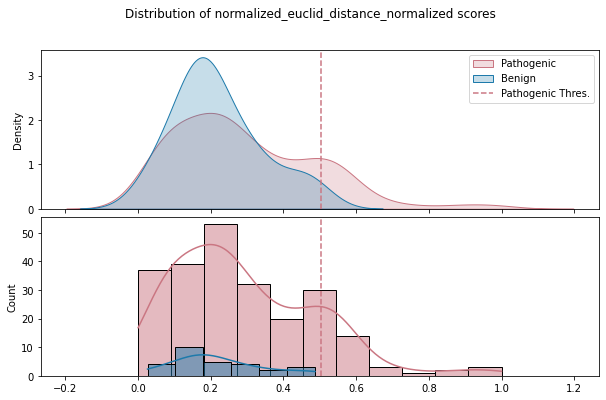

Benign: 0 (0.00%)
Pathogenic: 44 (18.80%)
VUS: 9 (9.89%)
Conflicting: 5 (6.67%)


In [377]:
plot_patho_benign(threshold=True)

In [400]:
orf_distances

db_orf_id,db_mut_id,euclid_distance,log2fc_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,cosine_distance,mean_log2fc,median_log2fc,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,ppi_hit
i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64
2713,838,0.869509,3.499453,0.474191,0.063212,0.474191,2.965919,2.965919,1.568479,1.568479,null,4.584122,0.038659,-0.793622,-0.801215,15,false,0.266667,-0.193696,-0.396671,0.191365,0.144815,0.337164,false,false,0.449457,false,false,0.266667,0.224506,1.183615,0.283046,"""MLH1""","""Ser508Arg""","""1524T>G""","""ENSG00000076242""","""Edgotyping3""","""4_VUS""",0.000001,2.0,"""MLH1_Ser508Arg""",0
9866,216928,0.286929,2.93159,0.230084,-0.733341,0.230084,4.690973,4.690973,2.229887,2.229887,null,2.620482,0.006155,-2.067801,-2.067801,2,true,1.0,-0.200759,-0.760083,0.037818,0.062337,0.213175,false,false,0.263096,true,false,1.0,0.20289,1.85296,0.255793,"""ZMYND10""","""Leu266Pro""","""797T>C""","""ENSG00000004838""","""CEGS2""","""1_Pathogenic""",null,1.0,"""ZMYND10_Leu266Pro""",0
2920,214437,0.305822,1.145988,-0.036816,0.862553,0.036816,0.917939,0.917939,-0.12353,0.12353,null,1.770064,0.021511,0.480726,0.450942,4,false,0.0,0.127432,0.428569,0.358998,0.319113,1.089397,true,false,0.323574,false,true,0.0,0.152911,0.885032,0.192782,"""GFAP""","""Glu371Gly""","""1112A>G""","""ENSG00000131095""","""CEGS2""","""5_Others""",null,null,"""GFAP_Glu371Gly""",0
71892,3998,0.150235,1.420914,0.125878,-0.366033,0.125878,2.396926,2.396926,1.261185,1.261185,null,1.193022,0.007847,-0.959066,-0.959066,2,false,0.5,-0.103943,-0.474416,0.153277,0.058707,0.417201,false,false,0.242307,false,false,0.5,0.106233,0.843594,0.133932,"""TH""","""Thr463Met""","""1388C>T""","""ENSG00000180176""","""Edgotyping3""","""3_Conflicting""",null,1.0,"""TH_Thr463Met""",0
11805,2123,0.457169,3.583087,0.405514,-0.703171,0.405514,8.74495,8.74495,3.12845,3.12845,null,2.139727,0.103604,-2.4395,-2.4395,2,true,1.0,-0.308306,-0.79441,0.129031,0.052358,0.114352,false,false,0.37904,true,false,1.0,0.323268,1.513016,0.407559,"""SMAD3""","""Cys109Tyr""","""326G>A""","""ENSG00000166949""","""Edgotyping3""","""4_VUS""",null,1.0,"""SMAD3_Cys109Tyr""",0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
70497,3874,0.31366,1.639306,0.31366,-0.679136,0.31366,3.116586,3.116586,1.639967,1.639967,null,1.423967,0.0,-1.639517,-1.639517,1,true,1.0,-0.31366,-0.679136,null,0.148192,0.320864,false,false,0.461852,true,false,1.0,0.31366,1.423967,0.395447,"""AGXT""","""Ala295Thr""","""883G>A""","""ENSG00000172482""","""Edgotyping3""","""3_Conflicting""",0.003015,1.0,"""AGXT_Ala295Thr""",0
13796,218139,0.0873,0.341635,0.034914,0.143337,0.034914,1.215799,1.215799,0.281905,0.281905,null,0.617833,0.004094,-0.044176,-0.044176,2,false,0.0,0.02255,-0.017079,0.226863,0.161789,0.822504,true,false,0.377464,false,true,0.0,0.06173,0.436874,0.077826,"""HBD""","""Gly26Asp""","""77G>A""","""ENSG00000223609""","""CEGS2""","""5_Others""",null,null,"""HBD_Gly26Asp""",0
3732,201253,0.273213,2.887304,0.273213,-0.865118,0.273213,7.413887,7.413887,2.89023,2.89023,null,2.535135,0.0,-2.889161,-2.889161,1,true,1.0,-0.273213,-0.865118,null,0.042597,0.134882,false,false,0.315811,true,false,1.0,0.273213,2.535135,0.344453,"""UROD""","""Met165Arg""","""494T>G

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_6362/2952331381.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_6362/2952331381.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others'], rotation=30)


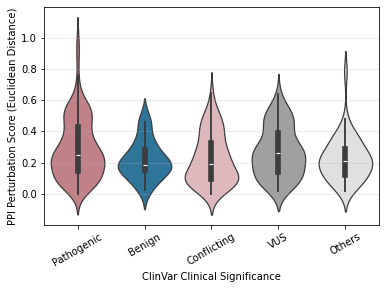

In [401]:
order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS", "5_Others"]

ax = sns.violinplot(
    data=orf_distances,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pillar"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others'], rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


In [378]:
# No filters
# Benign: 0 (0.00%)
# Pathogenic: 44 (18.80%)
# VUS: 9 (9.89%)
# Conflicting: 5 (6.67%)

In [379]:
## huge difference when filtering for size 1150 vs 1250, trying to find out how/why

In [380]:
# Calculate threshold from benign variants
path_thres = orf_distances.filter(pl.col("clinvar_clnsig_clean") == "2_Benign")["normalized_euclid_distance_normalized"].max() + 0.016

# Add ppi_hit column using polars with_columns
orf_distances = orf_distances.with_columns(
    (pl.col("normalized_euclid_distance_normalized") > path_thres).cast(pl.Int64).alias("ppi_hit")
)

orf_distances.filter(pl.col("ppi_hit") == 1).write_csv(f"./tmp/{size_value}_variant_ppi_hits.csv")

In [381]:
df_1150 = pd.read_csv(f"./tmp/1150_variant_ppi_hits.csv")
df_1250 = pd.read_csv(f"./tmp/1250_variant_ppi_hits.csv")

df_1150 = df_1150[df_1150.clinvar_clnsig_clean == "1_Pathogenic"]
df_1250 = df_1250[df_1250.clinvar_clnsig_clean == "1_Pathogenic"]

In [382]:
# filter df_1250 to only include rows that are not in df_1150 based on db_orf_id and db_mut_id
df_1250_unique = df_1250.merge(df_1150[['db_orf_id', 'db_mut_id']], on=['db_orf_id', 'db_mut_id'], how='left', indicator=True)
df_1250_unique = df_1250_unique[df_1250_unique['_merge'] == 'left_only'].drop(columns=['_merge'])
df_1250_unique

,db_orf_id,db_mut_id,euclid_distance,log2fc_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,...,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,ppi_hit
33,7652,1798,0.88673,4.187409,0.653478,-0.356481,0.653478,10.490529,10.490529,3.391015,...,STXBP1,Cys180Tyr,539G>A,ENSG00000136854,RC4,1_Pathogenic,NaN,1.0,STXBP1_Cys180Tyr,1


In [383]:
df_1150

,db_orf_id,db_mut_id,euclid_distance,log2fc_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,...,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,ppi_hit
0,70497,3789,0.402762,2.964321,0.402762,-0.872059,0.402762,7.816094,7.816094,2.966448,...,AGXT,Arg36Cys,106C>T,ENSG00000172482,Edgotyping3,1_Pathogenic,3.426300e-06,2.0,AGXT_Arg36Cys,1
1,7652,1832,1.043610,5.300396,0.644588,-0.686185,0.644588,9.291022,9.291022,3.215837,...,STXBP1,Leu426Pro,1277T>C,ENSG00000136854,Edgotyping3,1_Pathogenic,NaN,2.0,STXBP1_Leu426Pro,1
2,7982,202799,0.983948,13.099830,0.772331,-0.781202,0.772331,inf,inf,inf,...,HPRT1,Ile132Met,396T>G,ENSG00000165704,CEGS2,1_Pathogenic,NaN,NaN,HPRT1_Ile132Met,1
3,7652,1805,1.080148,5.535019,0.675582,-0.504084,0.675582,15.450371,15.450371,3.949570,...,STXBP1,Arg235Gln,704G>A,ENSG00000136854,Edgotyping3,1_Pathogenic,NaN,2.0,STXBP1_Arg235Gln,1
4,2713,4554,1.555411,11.123808,0.666977,-0.738212,0.666977,14.253753,14.253753,3.833270,...,MLH1,Ala586Asp,1757C>A,ENSG00000076242,RC4,1_Pathogenic,NaN,2.0,MLH1_Ala586Asp,1
5,100016069,2605,0.601362,4.190303,0.489282,-0.850982,0.489282,8.991652,8.991652,3.168586,...,KCNJ2,Arg67Gln,200G>A,ENSG00000123700,Edgotyping3,1_Pathogenic,NaN,2.0,KCNJ2_Arg67Gln,1
6,6018,215806,0.556054,3.567300,0.556054,-0.915791,0.556054,11.875214,11.875214,3.569882,...,ASNS,Ala6Glu,17C>A,ENSG00000070669,CEGS2,1_Pathogenic,NaN,2.0,ASNS_Ala6Glu,1
7,7652,1821,1.096545,5.436568,0.627073,-0.553597,0.627073,6.991005,6.991005,2.805500,...,STXBP1,Cys354Arg,1060T>C,ENSG00000136854,Edgotyping3,1_Pathogenic,NaN,2.0,STXBP1_Cys354Arg,1
9,7652,1809,1.036001,5.348215,0.664048,-0.485820,0.664048,12.392950,12.392950,3.631448,...,STXBP1,Leu256Pro,767T>C,ENSG00000136854,Edgotyping3,1_Pathogenic,NaN,1.0,STXBP1_Leu256Pro,1
11,7652,1846,1.031195,4.842974,0.648821,-0.602224,0.648821,9.825948,9.825948,3.296597,...,STXBP1,Arg551Leu,1652G>T,ENSG00000136854,Edgotyping3,1_Pathogenic,NaN,2.0,STXBP1_Arg551Leu,1


In [384]:
auto_df_full[(auto_df_full['db_orf_id'] == '2713.0') & (auto_df_full['db_mut_id'] == 1005)]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,consensus_score
4708,VUSAPWT1B1r01_025,C05,VUSAPWT1B1r01_025_026_027_028_029_030,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,VUSMutY8Dh011,E11,CEGSint_Y8A1_2_6,C01,NaN,4.0,2138,2,False,322.425715
4709,VUSAPWT1B1r01_025,C06,VUSAPWT1B1r01_025_026_027_028_029_030,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,VUSMutY8Dh011,E11,CEGSint_Y8A1_2_6,C01,0.000000,4.0,0,0,False,322.425715
4710,VUSAPWT1B1r01_025,C07,VUSAPWT1B1r01_025_026_027_028_029_030,VUSAPWT1B1,r07,LW,1.0,False,15066.0,NaN,...,VUSMutY8Dh011,E11,CEGSint_Y8A_3,F07,519.968637,4.0,1076,1,False,528.446094
4711,VUSAPWT1B1r01_025,C08,VUSAPWT1B1r01_025_026_027_028_029_030,VUSAPWT1B1,r07,LW,1.0,False,15066.0,NaN,...,VUSMutY8Dh011,E11,CEGSint_Y8A_3,F07,531.818322,4.0,1061,1,False,528.446094
4712,VUSAPWT1B1r01_025,C09,VUSAPWT1B1r01_025_026_027_028_029_030,VUSAPWT1B1,r07,LW,1.0,False,11922.0,NaN,...,VUSMutY8Dh011,E11,CEGSint_Y8A_6,D05,437.011774,3.0,921,1,False,514.994461
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
258830,VUSAPWT6B1r06_009,I16,VUSAPWT6B1r06_007_008_009_010_011_012,VUSAPWT6B1,r18,LWAH1,6.0,False,2658.0,NaN,...,VUSMutY8Dh011,E11,CEGSint_Y8A6_2,C09,0.000000,0.0,0,0,False,8.662092
258867,VUSAPWT6B1r06_009,J05,VUSAPWT6B1r06_007_008_009_010_011_012,VUSAPWT6B1,r18,LWAH1,6.0,False,4146.0,NaN,...,VUSMutY8Dh011,E11,CEGSint_Y8A6_1,E01,0.000000,0.0,0,0,False,0.692810
258868,VUSAPWT6B1r06_009,J06,VUSAPWT6B1r06_007_008_009_010_011_012,VUSAPWT6B1,r18,LWAH1,6.0,False,4146.0,NaN,...,VUSMutY8Dh011,E11,CEGSint_Y8A6_1,E01,0.000000,0.0,0,0,False,0.692810
258877,VUSAPWT6B1r06_009,J15,VUSAPWT6B1r06_007_008_009_010_011_012,VUSAPWT6B1,r18,LWAH1,6.0,False,2658.0,NaN,...,VUSMutY8Dh011,E11,CEGSint_Y8A6_2,C09,20.132026,0.0,52,1,False,8.662092


# Select medium based on last benign growth

In [385]:
scores_pd = scores.to_pandas()

# retain only scoring conditions
scores_pd = scores_pd[scores_pd.condition_name.isin(scoring_conditions)]

scores_pd = scores_pd[scores_pd.consensus_score == scores_pd.consensus_score]  # remove NaNs

# First, build WT media dict as fallback
wt_media_dict = {} 
min_growth_score = 200

for edge, df in scores_pd[scores_pd.db_mut_id == 0].groupby("edge_group"):
    for media in scoring_conditions:
        media_scores = df[df.condition_name == media]
        if not media_scores.empty and media_scores.consensus_score.values[0] >= min_growth_score:
            wt_media_dict[edge] = media

# Now build benign media dict
benign_media_dict = {}

for edge, df in scores_pd[scores_pd.clinvar_clnsig_clean == "2_Benign"].groupby("edge_group"):
    var_dict = {}
    for ppi, ppi_df in df.groupby("ppi_group"):
        var_dict[ppi] = []
        for media in scoring_conditions:
            media_scores = ppi_df[ppi_df.condition_name == media]
            if not media_scores.empty and media_scores.consensus_score.values[0] >= min_growth_score:
                var_dict[ppi].append(media)
                
    if len(var_dict) == 1:
        # only one variant for this edge, take the last media where it grew
        for ppi, media_list in var_dict.items():
            if media_list:
                benign_media_dict[edge] = media_list[-1]
    elif len(var_dict) > 1:
        # multiple benign variants. Take the last media of the most sensible variant (the one that grew in the least media)
        sorted_variants = sorted(var_dict.items(), key=lambda x: len(x[1]))
        for ppi, media_list in sorted_variants:
            if media_list:
                benign_media_dict[edge] = media_list[-1]
                break        

# Combine benign and WT media dicts with benign taking priority
combined_media_dict = {}
for edge in set(list(benign_media_dict.keys()) + list(wt_media_dict.keys())):
    if edge in benign_media_dict:
        combined_media_dict[edge] = benign_media_dict[edge]
        # print(f"Edge {edge}: Using benign methodology -> {benign_media_dict[edge]}")
    elif edge in wt_media_dict:
        combined_media_dict[edge] = wt_media_dict[edge]
        # print(f"Edge {edge}: Fallback to WT methodology -> {wt_media_dict[edge]}")
    # If edge is in neither dict, it will be skipped

print(f"Total edges with benign variants: {len(benign_media_dict)}")
print(f"Total edges with WT fallback: {len(wt_media_dict) - len(benign_media_dict)}")
print(f"Total edges covered: {len(combined_media_dict)}")


            
# Now filter all scores to only include medium where the WT grew
filtered_scores_benigns = []
for edge, df in scores_pd.groupby("edge_group"):
    if edge in combined_media_dict:
        valid_media = combined_media_dict[edge]
        filtered_df = df[df.condition_name == valid_media]
        filtered_scores_benigns.append(filtered_df)
    # if edge not in wt_media_dict:
        # print(f"Edge {edge} not found in WT media dict, skipping.")
        
if filtered_scores_benigns:
    filtered_scores_benigns = pd.concat(filtered_scores_benigns, ignore_index=True)
    print(f"Filtered scores shape: {filtered_scores_benigns.shape}")
    
# filter for edges with at least a variant and a WT
print(f"Total unique ppis before filtering: {filtered_scores_benigns['ppi_group'].nunique()}")
valid_edges_benigns = filtered_scores_benigns.groupby("edge_group").filter(lambda x: (x.db_mut_id == 0).any() and (x.db_mut_id != 0).any())
print(f"Valid ppis after filtering: {valid_edges_benigns['ppi_group'].nunique()}")
    

valid_edges_benigns_pl = pl.from_pandas(valid_edges_benigns)

# add wt_consensus_score column to compute log2fc

wt_scores = valid_edges_benigns_pl.filter(pl.col("db_mut_id") == 0).select(
        [
            "edge_group", "consensus_score"
        ]
    ).rename({"consensus_score": "wt_consensus_score"})

valid_edges_benigns_pl = valid_edges_benigns_pl.join(
    wt_scores,
    on=["edge_group"],
    how="left"
)

# Compute log2fc
valid_edges_benigns_pl = valid_edges_benigns_pl.with_columns(
    np.log2(((pl.col("consensus_score") + 1) / (pl.col("wt_consensus_score") + 1)).alias("log2fc")
))

valid_edges_benigns_pl


Total edges with benign variants: 79
Total edges with WT fallback: 709
Total edges covered: 800
Filtered scores shape: (2187, 41)
Total unique ppis before filtering: 2187
Valid ppis after filtering: 1552


scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,i64,i64,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64,f64,f64,f64
"""VUSAPWT6B1r05_010""","""A01""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""","""6""",false,100000046,null,7323,216370,"""VUSMutY8Dh020""","""B07""","""CEGSint_Y8A6_1""","""H03""",616.734667,3.0,1115,1,false,590.969958,"""CLDN5""","""PMP22""","""Gly150Cys""","""448G>T""","""ENSG00000109099""","""CEGS2""","""3_Conflicting""",null,1.0,"""PMP22_Gly150Cys""","""7323.0_216370.0""","""7323.0_216370.0_LWH25_VUSAPWT6…","""100000046.0_7323.0_216370.0_VU…","""100000046.0_7323.0_VUSAPWT6B1""","""1""","""1""","""Y""",66.72255,3.0,398.327791,0.56795
"""VUSAPWT6B1r05_010""","""E01""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""","""6""",false,100000046,null,7323,216371,"""VUSMutY8Dh020""","""H06""","""CEGSint_Y8A6_1""","""H03""",546.500673,3.0,1078,1,false,395.359817,"""CLDN5""","""PMP22""","""Arg157Trp""","""469C>T""","""ENSG00000109099""","""CEGS2""","""1_Pathogenic""",null,2.0,"""PMP22_Arg157Trp""","""7323.0_216371.0""","""7323.0_216371.0_LWH25_VUSAPWT6…","""100000046.0_7323.0_216371.0_VU…","""100000046.0_7323.0_VUSAPWT6B1""","""1""","""1""","""Y""",166.175165,3.0,398.327791,-0.010763
"""VUSAPWT6B1r05_009""","""K23""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""","""6""",false,100000046,null,7323,0,"""DisWTY8Dh02""","""D09""","""CEGSint_Y8A6_1""","""H03""",0.0,3.0,0,0,false,398.327791,"""CLDN5""","""PMP22""",null,null,"""ENSG00000109099""",null,null,null,null,"""PMP22""","""7323.0_0.0""","""7323.0_0.0_LWH25_VUSAPWT6B1""","""100000046.0_7323.0_0.0_VUSAPWT…","""100000046.0_7323.0_VUSAPWT6B1""","""1""","""1""",null,51.665687,3.0,398.327791,0.0
"""VUSAPWT1B2r03_008""","""I03""","""VUSAPWT1B2r03_007_008_009_010_…","""VUSAPWT1B2""","""r09""","""LWH1""","""1""",false,100000407,null,53965,0,"""DisWTY8Dh02""","""E12""","""CEGSint_Y8A_3""","""E04""",418.960792,3.0,886,1,false,434.028112,"""PICK1""","""SMARCB1""",null,null,"""ENSG00000099956""",null,null,null,null,"""SMARCB1""","""53965.0_0.0""","""53965.0_0.0_LWH1_VUSAPWT1B2""","""100000407.0_53965.0_0.0_VUSAPW…","""100000407.0_53965.0_VUSAPWT1B2""","""1""","""1""",null,40.631373,3.0,434.028112,0.0
"""VUSAPWT1B2r03_020""","""I11""","""VUSAPWT1B2r03_019_020_021_022_…","""VUSAPWT1B2""","""r09""","""LWH1""","""1""",false,100000407,null,53965,204888,"""VUSMutY8Dh028""","""H02""","""CEGSint_Y8A_3""","""E04""",54.798694,0.0,135,1,false,33.988563,"""PICK1""","""SMARCB1""","""Pro48Leu""","""143C>T""","""ENSG00000099956""","""CEGS2""","""4_VUS""",null,1.0,"""SMARCB1_Pro48Leu""","""53965.0_204888.0""","""53965.0_204888.0_LWH1_VUSAPWT1…","""100000407.0_53965.0_204888.0_V…","""100000407.0_53965.0_VUSAPWT1B2""","""1""","""1""","""Y""",44.704249,0.0,434.028112,-3.636153
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r05_029""","""G05""","""VUSAPWT1B1r05_025_026_027_028_…","""VUSAPWT1B1""","""r11""","""LWH25""","""1""",false,9746,null,54308,3133,"""VUSMutY8Dh015""","""F06""","""CEGSint_Y8A_6""","""C02""",227.593469,2.0,542,3,false,104.096734,"""MTUS2""","""PKP2""","""Gly68Ser""","""202G>A""","""ENSG00000057294""","""Edgotyping3""","""4_VUS""",null,2.0,"""PKP2_Gly68Ser""","""54308.0_3133.0""","""54308.0_3133.0_LWH25_VU

In [386]:
failed_orfs = [143, 7651, 8965, 12739]

In [387]:
filtered_scores_benigns[filtered_scores_benigns.db_orf_id == 7651]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth


In [388]:
# wt_media_dict['56717.0_7651.0_VUSAPWT1B2']

In [389]:
scores_300_pd = scores_300.to_pandas()

In [390]:
auto_df_full[(auto_df_full.db_orf_id == '7651.0') & (auto_df_full.db_mut_id == 0.0) & (auto_df_full.condition_name == 'LWH1')]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,consensus_score
90261,VUSAPWT1B2r03_007,I23,VUSAPWT1B2r03_007_008_009_010_011_012,VUSAPWT1B2,r09,LWH1,1.0,False,0.0,NaN,...,DisWTY8Dh02,B12,CEGSint_Y8A1_2_6,A01,16.562092,0.0,39,2,False,13.237582
90262,VUSAPWT1B2r03_007,I24,VUSAPWT1B2r03_007_008_009_010_011_012,VUSAPWT1B2,r09,LWH1,1.0,False,0.0,NaN,...,DisWTY8Dh02,B12,CEGSint_Y8A1_2_6,A01,0.000000,0.0,0,0,False,13.237582
90309,VUSAPWT1B2r03_007,J23,VUSAPWT1B2r03_007_008_009_010_011_012,VUSAPWT1B2,r09,LWH1,1.0,False,0.0,NaN,...,DisWTY8Dh02,B12,CEGSint_Y8A1_2_6,A01,0.000000,0.0,0,0,False,13.237582
90310,VUSAPWT1B2r03_007,J24,VUSAPWT1B2r03_007_008_009_010_011_012,VUSAPWT1B2,r09,LWH1,1.0,False,0.0,NaN,...,DisWTY8Dh02,B12,CEGSint_Y8A1_2_6,A01,36.388236,0.0,85,1,False,13.237582
90357,VUSAPWT1B2r03_007,K23,VUSAPWT1B2r03_007_008_009_010_011_012,VUSAPWT1B2,r09,LWH1,1.0,False,56717.0,NaN,...,DisWTY8Dh02,B12,CEGSint_Y8A_5,H09,24.935948,0.0,59,1,False,NaN
90358,VUSAPWT1B2r03_007,K24,VUSAPWT1B2r03_007_008_009_010_011_012,VUSAPWT1B2,r09,LWH1,1.0,False,56717.0,NaN,...,DisWTY8Dh02,B12,CEGSint_Y8A_5,H09,629.575192,0.0,1119,1,False,NaN
90405,VUSAPWT1B2r03_007,L23,VUSAPWT1B2r03_007_008_009_010_011_012,VUSAPWT1B2,r09,LWH1,1.0,False,56717.0,NaN,...,DisWTY8Dh02,B12,CEGSint_Y8A_5,H09,28.596079,0.0,68,1,False,NaN
90406,VUSAPWT1B2r03_007,L24,VUSAPWT1B2r03_007_008_009_010_011_012,VUSAPWT1B2,r09,LWH1,1.0,False,56717.0,NaN,...,DisWTY8Dh02,B12,CEGSint_Y8A_5,H09,649.554278,0.0,1216,3,False,NaN


In [391]:
scores_300_pd[scores_300_pd.db_orf_id == 7651]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
3509,VUSAPWT1B2r01_007,K23,VUSAPWT1B2r01_007_008_009_010_011_012,VUSAPWT1B2,r07,LW,1,False,56717,NaN,...,NaN,IL2RG,7651.0_0.0,7651.0_0.0_LW_VUSAPWT1B2,56717.0_7651.0_0.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,None,467.841840
3817,VUSAPWT1B2r01_020,K05,VUSAPWT1B2r01_019_020_021_022_023_024,VUSAPWT1B2,r07,LW,1,False,56717,NaN,...,2.0,IL2RG_Tyr105Cys,7651.0_216443.0,7651.0_216443.0_LW_VUSAPWT1B2,56717.0_7651.0_216443.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,Y,496.249355
4841,VUSAPWT1B2r02_007,K23,VUSAPWT1B2r02_007_008_009_010_011_012,VUSAPWT1B2,r08,LWA,1,False,56717,NaN,...,NaN,IL2RG,7651.0_0.0,7651.0_0.0_LWA_VUSAPWT1B2,56717.0_7651.0_0.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,None,0.000000
5149,VUSAPWT1B2r02_020,K05,VUSAPWT1B2r02_019_020_021_022_023_024,VUSAPWT1B2,r08,LWA,1,False,56717,NaN,...,2.0,IL2RG_Tyr105Cys,7651.0_216443.0,7651.0_216443.0_LWA_VUSAPWT1B2,56717.0_7651.0_216443.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,Y,0.894771
6149,VUSAPWT1B2r03_007,K23,VUSAPWT1B2r03_007_008_009_010_011_012,VUSAPWT1B2,r09,LWH1,1,False,56717,NaN,...,NaN,IL2RG,7651.0_0.0,7651.0_0.0_LWH1_VUSAPWT1B2,56717.0_7651.0_0.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,None,13.237582
6445,VUSAPWT1B2r03_020,K05,VUSAPWT1B2r03_019_020_021_022_023_024,VUSAPWT1B2,r09,LWH1,1,False,56717,NaN,...,2.0,IL2RG_Tyr105Cys,7651.0_216443.0,7651.0_216443.0_LWH1_VUSAPWT1B2,56717.0_7651.0_216443.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,Y,55.728759
7431,VUSAPWT1B2r04_007,K23,VUSAPWT1B2r04_007_008_009_010_011_012,VUSAPWT1B2,r10,LWH10,1,False,56717,NaN,...,NaN,IL2RG,7651.0_0.0,7651.0_0.0_LWH10_VUSAPWT1B2,56717.0_7651.0_0.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,None,0.000000
7738,VUSAPWT1B2r04_020,K05,VUSAPWT1B2r04_019_020_021_022_023_024,VUSAPWT1B2,r10,LWH10,1,False,56717,NaN,...,2.0,IL2RG_Tyr105Cys,7651.0_216443.0,7651.0_216443.0_LWH10_VUSAPWT1B2,56717.0_7651.0_216443.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,Y,8.869281
8729,VUSAPWT1B2r05_007,K23,VUSAPWT1B2r05_007_008_009_010_011_012,VUSAPWT1B2,r11,LWH25,1,False,56717,NaN,...,NaN,IL2RG,7651.0_0.0,7651.0_0.0_LWH25_VUSAPWT1B2,56717.0_7651.0_0.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,None,39.977125
9037,VUSAPWT1B2r05_020,K05,VUSAPWT1B2r05_019_020_021_022_023_024,VUSAPWT1B2,r11,LWH25,1,False,56717,NaN,...,2.0,IL2RG_Tyr105Cys,7651.0_216443.0,7651.0_216443.0_LWH25_VUSAPWT1B2,56717.0_7651.0_216443.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,Y,58.483661


In [392]:
scores_pd[scores_pd.db_orf_id == 7651]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth
4170,VUSAPWT1B2r02_007,K23,VUSAPWT1B2r02_007_008_009_010_011_012,VUSAPWT1B2,r08,LWA,1,False,56717,NaN,...,IL2RG,7651.0_0.0,7651.0_0.0_LWA_VUSAPWT1B2,56717.0_7651.0_0.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,None,0.000000,0.0
4442,VUSAPWT1B2r02_020,K05,VUSAPWT1B2r02_019_020_021_022_023_024,VUSAPWT1B2,r08,LWA,1,False,56717,NaN,...,IL2RG_Tyr105Cys,7651.0_216443.0,7651.0_216443.0_LWA_VUSAPWT1B2,56717.0_7651.0_216443.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,Y,0.894771,0.0
5598,VUSAPWT1B2r03_020,K05,VUSAPWT1B2r03_019_020_021_022_023_024,VUSAPWT1B2,r09,LWH1,1,False,56717,NaN,...,IL2RG_Tyr105Cys,7651.0_216443.0,7651.0_216443.0_LWH1_VUSAPWT1B2,56717.0_7651.0_216443.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,Y,55.728759,0.0
6483,VUSAPWT1B2r04_007,K23,VUSAPWT1B2r04_007_008_009_010_011_012,VUSAPWT1B2,r10,LWH10,1,False,56717,NaN,...,IL2RG,7651.0_0.0,7651.0_0.0_LWH10_VUSAPWT1B2,56717.0_7651.0_0.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,None,0.000000,0.0
6754,VUSAPWT1B2r04_020,K05,VUSAPWT1B2r04_019_020_021_022_023_024,VUSAPWT1B2,r10,LWH10,1,False,56717,NaN,...,IL2RG_Tyr105Cys,7651.0_216443.0,7651.0_216443.0_LWH10_VUSAPWT1B2,56717.0_7651.0_216443.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,Y,8.869281,0.0
7644,VUSAPWT1B2r05_007,K23,VUSAPWT1B2r05_007_008_009_010_011_012,VUSAPWT1B2,r11,LWH25,1,False,56717,NaN,...,IL2RG,7651.0_0.0,7651.0_0.0_LWH25_VUSAPWT1B2,56717.0_7651.0_0.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,None,39.977125,0.0
7916,VUSAPWT1B2r05_020,K05,VUSAPWT1B2r05_019_020_021_022_023_024,VUSAPWT1B2,r11,LWH25,1,False,56717,NaN,...,IL2RG_Tyr105Cys,7651.0_216443.0,7651.0_216443.0_LWH25_VUSAPWT1B2,56717.0_7651.0_216443.0_VUSAPWT1B2,56717.0_7651.0_VUSAPWT1B2,1,1,Y,58.483661,0.0


In [393]:
auto_df_full[(auto_df_full.db_orf_id == '143.0') & (auto_df_full.db_mut_id == 213584.0) & (auto_df_full.condition_name == 'LWH25')]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,consensus_score
131135,VUSAPWT1B2r05_027,M01,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1.0,False,0.0,NaN,...,VUSMutY8Dh029,E08,CEGSint_Y8A1_2_6,C01,336.330722,0.0,772,1,False,164.219936
131136,VUSAPWT1B2r05_027,M02,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1.0,False,0.0,NaN,...,VUSMutY8Dh029,E08,CEGSint_Y8A1_2_6,C01,86.593465,0.0,203,1,False,164.219936
131183,VUSAPWT1B2r05_027,N01,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1.0,False,0.0,NaN,...,VUSMutY8Dh029,E08,CEGSint_Y8A1_2_6,C01,142.011766,0.0,330,1,False,164.219936
131184,VUSAPWT1B2r05_027,N02,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1.0,False,0.0,NaN,...,VUSMutY8Dh029,E08,CEGSint_Y8A1_2_6,C01,91.943792,0.0,219,1,False,164.219936
131231,VUSAPWT1B2r05_027,O01,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1.0,False,14891.0,NaN,...,VUSMutY8Dh029,E08,CEGSint_Y8A_2,H10,518.023541,2.0,1109,3,False,NaN
131232,VUSAPWT1B2r05_027,O02,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1.0,False,14891.0,NaN,...,VUSMutY8Dh029,E08,CEGSint_Y8A_2,H10,553.532033,2.0,1211,2,False,NaN
131279,VUSAPWT1B2r05_027,P01,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1.0,False,14891.0,NaN,...,VUSMutY8Dh029,E08,CEGSint_Y8A_2,H10,173.367323,2.0,393,3,False,NaN
131280,VUSAPWT1B2r05_027,P02,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1.0,False,14891.0,NaN,...,VUSMutY8Dh029,E08,CEGSint_Y8A_2,H10,1.729412,2.0,4,1,False,NaN


In [394]:
# map ad_orf_id to ad_symbol
mapping_file = pd.read_csv(f"{inputs_dirs}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

valid_edges_benigns_pl = valid_edges_benigns_pl.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)
valid_edges_benigns_pl

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,i64,i64,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64,f64,f64,f64
"""VUSAPWT6B1r05_010""","""A01""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""","""6""",false,100000046,null,7323,216370,"""VUSMutY8Dh020""","""B07""","""CEGSint_Y8A6_1""","""H03""",616.734667,3.0,1115,1,false,590.969958,"""CLDN5""","""PMP22""","""Gly150Cys""","""448G>T""","""ENSG00000109099""","""CEGS2""","""3_Conflicting""",null,1.0,"""PMP22_Gly150Cys""","""7323.0_216370.0""","""7323.0_216370.0_LWH25_VUSAPWT6…","""100000046.0_7323.0_216370.0_VU…","""100000046.0_7323.0_VUSAPWT6B1""","""1""","""1""","""Y""",66.72255,3.0,398.327791,0.56795
"""VUSAPWT6B1r05_010""","""E01""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""","""6""",false,100000046,null,7323,216371,"""VUSMutY8Dh020""","""H06""","""CEGSint_Y8A6_1""","""H03""",546.500673,3.0,1078,1,false,395.359817,"""CLDN5""","""PMP22""","""Arg157Trp""","""469C>T""","""ENSG00000109099""","""CEGS2""","""1_Pathogenic""",null,2.0,"""PMP22_Arg157Trp""","""7323.0_216371.0""","""7323.0_216371.0_LWH25_VUSAPWT6…","""100000046.0_7323.0_216371.0_VU…","""100000046.0_7323.0_VUSAPWT6B1""","""1""","""1""","""Y""",166.175165,3.0,398.327791,-0.010763
"""VUSAPWT6B1r05_009""","""K23""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""","""6""",false,100000046,null,7323,0,"""DisWTY8Dh02""","""D09""","""CEGSint_Y8A6_1""","""H03""",0.0,3.0,0,0,false,398.327791,"""CLDN5""","""PMP22""",null,null,"""ENSG00000109099""",null,null,null,null,"""PMP22""","""7323.0_0.0""","""7323.0_0.0_LWH25_VUSAPWT6B1""","""100000046.0_7323.0_0.0_VUSAPWT…","""100000046.0_7323.0_VUSAPWT6B1""","""1""","""1""",null,51.665687,3.0,398.327791,0.0
"""VUSAPWT1B2r03_008""","""I03""","""VUSAPWT1B2r03_007_008_009_010_…","""VUSAPWT1B2""","""r09""","""LWH1""","""1""",false,100000407,null,53965,0,"""DisWTY8Dh02""","""E12""","""CEGSint_Y8A_3""","""E04""",418.960792,3.0,886,1,false,434.028112,"""PICK1""","""SMARCB1""",null,null,"""ENSG00000099956""",null,null,null,null,"""SMARCB1""","""53965.0_0.0""","""53965.0_0.0_LWH1_VUSAPWT1B2""","""100000407.0_53965.0_0.0_VUSAPW…","""100000407.0_53965.0_VUSAPWT1B2""","""1""","""1""",null,40.631373,3.0,434.028112,0.0
"""VUSAPWT1B2r03_020""","""I11""","""VUSAPWT1B2r03_019_020_021_022_…","""VUSAPWT1B2""","""r09""","""LWH1""","""1""",false,100000407,null,53965,204888,"""VUSMutY8Dh028""","""H02""","""CEGSint_Y8A_3""","""E04""",54.798694,0.0,135,1,false,33.988563,"""PICK1""","""SMARCB1""","""Pro48Leu""","""143C>T""","""ENSG00000099956""","""CEGS2""","""4_VUS""",null,1.0,"""SMARCB1_Pro48Leu""","""53965.0_204888.0""","""53965.0_204888.0_LWH1_VUSAPWT1…","""100000407.0_53965.0_204888.0_V…","""100000407.0_53965.0_VUSAPWT1B2""","""1""","""1""","""Y""",44.704249,0.0,434.028112,-3.636153
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r05_029""","""G05""","""VUSAPWT1B1r05_025_026_027_028_…","""VUSAPWT1B1""","""r11""","""LWH25""","""1""",false,9746,null,54308,3133,"""VUSMutY8Dh015""","""F06""","""CEGSint_Y8A_6""","""C02""",227.593469,2.0,542,3,false,104.096734,"""MTUS2""","""PKP2""","""Gly68Ser""","""202G>A""","""ENSG00000057294""","""Edgotyping3""","""4_VUS""",null,2.0,"""PKP2_Gly68Ser""","""54308.0_3133.0""","""54308.0_3133.0_LWH25_VU

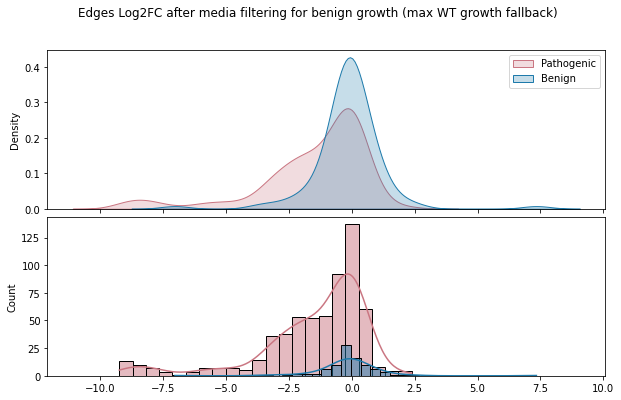

In [395]:
plot_patho_benign(scores=valid_edges_benigns_pl, metric="log2fc", title="Edges Log2FC after media filtering for benign growth (max WT growth fallback)")

# Auroc - PR curves


APPROACH 3: Media filtered by benign growth (WT fallback)


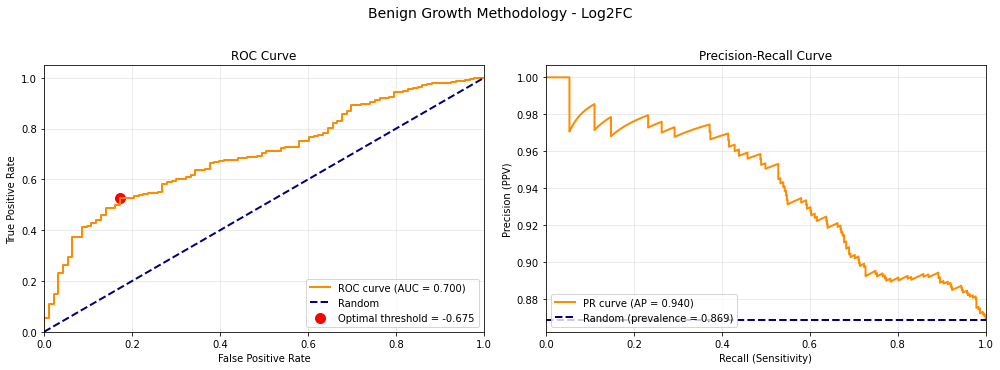


Classification Performance: Benign Growth Methodology - Log2FC
Dataset: 708 variants (615 pathogenic, 93 benign)

Area Under ROC Curve (AUROC): 0.7003
Area Under PR Curve (AUPRC):  0.9397

Optimal Threshold (Youden): -0.6755

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.5285
  Specificity:           0.8280
  Precision (PPV):       0.9531
  Negative Pred. Value:  0.2098
  Accuracy:              0.5678



In [396]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_classification_performance(scores_df, metric_col, title=None, filter_edges=None):
    """
    Calculate AUROC and Precision-Recall metrics for benign vs pathogenic classification.
    
    Parameters:
    -----------
    scores_df : polars.DataFrame
        DataFrame containing scores and clinical significance
    metric_col : str
        Name of the column containing the metric to evaluate (e.g., 'log2fc')
    title : str, optional
        Title for the plots
    filter_edges : int, optional
        Minimum number of edges required to include a variant
    
    Returns:
    --------
    dict : Dictionary containing AUROC, AUPRC, and other metrics
    """
    
    # Convert to pandas for sklearn compatibility
    scores_pd = scores_df.to_pandas()
    
    # Filter by number of edges if specified
    if filter_edges is not None and 'num_edges' in scores_pd.columns:
        scores_pd = scores_pd[scores_pd['num_edges'] >= filter_edges]
    
    # Filter to only benign and pathogenic
    filtered = scores_pd[scores_pd['clinvar_clnsig_clean'].isin(['1_Pathogenic', '2_Benign'])].copy()
    
    # Remove NaN values in metric column
    filtered = filtered[filtered[metric_col].notna()]
    
    if len(filtered) < 10:
        print(f"Warning: Only {len(filtered)} variants available for evaluation")
        return None
    
    # Create binary labels (1 = Pathogenic, 0 = Benign)
    y_true = (filtered['clinvar_clnsig_clean'] == '1_Pathogenic').astype(int)
    y_scores = filtered[metric_col].values
    
    # For log2fc, more negative = more pathogenic, so we negate for ROC
    # Adjust this based on your metric interpretation
    y_scores_roc = -y_scores  # Negative log2fc indicates loss of function (pathogenic)
    
    # Calculate ROC curve and AUROC
    fpr, tpr, roc_thresholds = roc_curve(y_true, y_scores_roc)
    roc_auc = auc(fpr, tpr)
    
    # Calculate Precision-Recall curve and AUPRC
    precision, recall, pr_thresholds = precision_recall_curve(y_true, y_scores_roc)
    auprc = average_precision_score(y_true, y_scores_roc)
    
    # Calculate optimal threshold (Youden's index for ROC)
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold_roc = -roc_thresholds[optimal_idx]  # Convert back to original scale
    
    # Create plots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # ROC Curve
    axes[0].plot(fpr, tpr, color='darkorange', lw=2, 
                 label=f'ROC curve (AUC = {roc_auc:.3f})')
    axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
    axes[0].scatter(fpr[optimal_idx], tpr[optimal_idx], marker='o', color='red', 
                    s=100, label=f'Optimal threshold = {optimal_threshold_roc:.3f}')
    axes[0].set_xlim([0.0, 1.0])
    axes[0].set_ylim([0.0, 1.05])
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title('ROC Curve')
    axes[0].legend(loc="lower right")
    axes[0].grid(alpha=0.3)
    
    # Precision-Recall Curve
    axes[1].plot(recall, precision, color='darkorange', lw=2,
                 label=f'PR curve (AP = {auprc:.3f})')
    axes[1].axhline(y=y_true.mean(), color='navy', linestyle='--', lw=2,
                    label=f'Random (prevalence = {y_true.mean():.3f})')
    axes[1].set_xlim([0.0, 1.0])
    # axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel('Recall (Sensitivity)')
    axes[1].set_ylabel('Precision (PPV)')
    axes[1].set_title('Precision-Recall Curve')
    axes[1].legend(loc="lower left")
    axes[1].grid(alpha=0.3)
    
    if title:
        fig.suptitle(title, fontsize=14, y=1.02)
    
    plt.tight_layout()
    plt.show()
    
    # Calculate additional metrics at optimal threshold
    y_pred_optimal = (y_scores_roc >= roc_thresholds[optimal_idx]).astype(int)
    
    tp = np.sum((y_pred_optimal == 1) & (y_true == 1))
    fp = np.sum((y_pred_optimal == 1) & (y_true == 0))
    tn = np.sum((y_pred_optimal == 0) & (y_true == 0))
    fn = np.sum((y_pred_optimal == 0) & (y_true == 1))
    
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    # Print summary
    print(f"\n{'='*60}")
    print(f"Classification Performance: {title if title else metric_col}")
    print(f"{'='*60}")
    print(f"Dataset: {len(filtered)} variants ({y_true.sum()} pathogenic, {len(y_true) - y_true.sum()} benign)")
    print(f"\nArea Under ROC Curve (AUROC): {roc_auc:.4f}")
    print(f"Area Under PR Curve (AUPRC):  {auprc:.4f}")
    print(f"\nOptimal Threshold (Youden): {optimal_threshold_roc:.4f}")
    print(f"\nPerformance at Optimal Threshold:")
    print(f"  Sensitivity (Recall):  {sensitivity:.4f}")
    print(f"  Specificity:           {specificity:.4f}")
    print(f"  Precision (PPV):       {ppv:.4f}")
    print(f"  Negative Pred. Value:  {npv:.4f}")
    print(f"  Accuracy:              {accuracy:.4f}")
    print(f"{'='*60}\n")
    
    # Return metrics dictionary
    return {
        'auroc': roc_auc,
        'auprc': auprc,
        'optimal_threshold': optimal_threshold_roc,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'precision': ppv,
        'npv': npv,
        'accuracy': accuracy,
        'n_variants': len(filtered),
        'n_pathogenic': y_true.sum(),
        'n_benign': len(y_true) - y_true.sum(),
        'fpr': fpr,
        'tpr': tpr,
        'roc_thresholds': roc_thresholds,
        'precision_curve': precision,
        'recall_curve': recall,
        'pr_thresholds': pr_thresholds
    }


# 3. Benign growth methodology (with WT fallback)
print("\n" + "="*80)
print("APPROACH 3: Media filtered by benign growth (WT fallback)")
print("="*80)
results_benign = evaluate_classification_performance(
    valid_edges_benigns_pl.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc',
    title='Benign Growth Methodology - Log2FC'
)


# orf distances

In [403]:
# Filter to keep only genes that have at least one allele tested and reference WT measurement

orfs_with_alleles = valid_edges_benigns_pl.filter(pl.col("db_mut_id") != 0).select("db_orf_id").unique().to_series().to_list()
orfs = valid_edges_benigns_pl.filter(pl.col("db_mut_id") == 0).select("db_orf_id").unique().to_series().to_list()

complete_orf_pairs = [i for i in orfs if i in orfs_with_alleles]
valid_edges_benigns_pl = valid_edges_benigns_pl.filter(pl.col("db_orf_id").is_in(complete_orf_pairs))
genes = valid_edges_benigns_pl.select("db_orf_id").to_series().unique().to_list()

# Since scores were summed across conditions, there should be only one entry per ad_orf_id, db_orf_id, db_mut_id, retest_batch combination

valid_edges_benigns_pl = valid_edges_benigns_pl.unique(subset=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"])


print(valid_edges_benigns_pl.select(pl.col('db_orf_id')).n_unique())

# normalize consensus score based on max score
valid_edges_benigns_pl = valid_edges_benigns_pl.with_columns(
    (pl.col("consensus_score") / max_score).alias("consensus_score_normalized"),
    (pl.col("wt_consensus_score") / max_score).alias("wt_consensus_score_normalized"),
)



valid_edges_benigns_pl


69


scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc,consensus_score_normalized,wt_consensus_score_normalized
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,i64,i64,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64
"""VUSAPWT1B1r02_017""","""G05""","""VUSAPWT1B1r02_013_014_015_016_…","""VUSAPWT1B1""","""r08""","""LWA""","""1""",false,71001,null,52920,2689,"""VUSMutY8Dh007""","""B02""","""CEGSint_Y8A_5""","""F07""",475.887588,4.0,1085,1,false,434.281379,"""UBQLN2""","""LITAF""","""Ser15Leu""","""44C>T""","""ENSG00000189067""","""Edgotyping3""","""3_Conflicting""",null,1.0,"""LITAF_Ser15Leu""","""52920.0_2689.0""","""52920.0_2689.0_LWA_VUSAPWT1B1""","""71001.0_52920.0_2689.0_VUSAPWT…","""71001.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",0.0,4.0,534.409823,-0.298695,0.579042,0.712546
"""VUSAPWT1B2r05_008""","""M15""","""VUSAPWT1B2r05_007_008_009_010_…","""VUSAPWT1B2""","""r11""","""LWH25""","""1""",false,55351,null,2920,0,"""DisWTY8Dh03""","""A03""","""CEGSint_Y8A_1""","""E02""",234.227454,0.0,561,3,false,209.000983,"""TP53BP2""","""GFAP""",null,null,"""ENSG00000131095""",null,null,null,null,"""GFAP""","""2920.0_0.0""","""2920.0_0.0_LWH25_VUSAPWT1B2""","""55351.0_2920.0_0.0_VUSAPWT1B2""","""55351.0_2920.0_VUSAPWT1B2""","""1""","""1""",null,35.410458,0.0,209.000983,0.0,0.278668,0.278668
"""VUSAPWT2B1r05_004""","""G23""","""VUSAPWT2B1r05_001_002_003_004_…","""VUSAPWT2B1""","""r17""","""LWH25""","""2""",false,10677,null,2713,473,"""VUSMutY8Dh011""","""F08""","""CEGSint_Y8A2_2""","""B05""",95.338564,0.0,210,1,false,78.684641,"""KPNA5""","""MLH1""","""Cys39Phe""","""116G>T""","""ENSG00000076242""","""Edgotyping3""","""4_VUS""",null,3.0,"""MLH1_Cys39Phe""","""2713.0_473.0""","""2713.0_473.0_LWH25_VUSAPWT2B1""","""10677.0_2713.0_473.0_VUSAPWT2B…","""10677.0_2713.0_VUSAPWT2B1""","""1""","""1""","""Y""",103.693465,0.0,132.197061,-0.741189,0.104913,0.176263
"""VUSAPWT6B1r02_020""","""I15""","""VUSAPWT6B1r02_019_020_021_022_…","""VUSAPWT6B1""","""r14""","""LWA""","""6""",false,487,null,3535,201190,"""VUSMutY8Dh018""","""D11""","""CEGSint_Y8A6_1""","""B05""",561.790872,4.0,1090,1,false,537.245445,"""LIME1""","""EMD""","""Met1Val""","""1A>G""","""ENSG00000102119""","""CEGS2""","""1_Pathogenic""",9.5000e-7,2.0,"""EMD_Met1Val""","""3535.0_201190.0""","""3535.0_201190.0_LWA_VUSAPWT6B1""","""487.0_3535.0_201190.0_VUSAPWT6…","""487.0_3535.0_VUSAPWT6B1""","""1""","""1""","""Y""",0.0,4.0,571.349698,-0.088633,0.716327,0.7618
"""VUSAPWT6B1r05_008""","""M09""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""","""6""",false,14404,null,2713,1005,"""VUSMutY8Dh011""","""E11""","""CEGSint_Y8A6_2""","""B04""",44.937255,0.0,105,1,false,52.909151,"""SPATA8""","""MLH1""","""Gln701His""","""2103G>C""","""ENSG00000076242""","""Edgotyping3""","""1_Pathogenic""",null,3.0,"""MLH1_Gln701His""","""2713.0_1005.0""","""2713.0_1005.0_LWH25_VUSAPWT6B1""","""14404.0_2713.0_1005.0_VUSAPWT6…","""14404.0_2713.0_VUSAPWT6B1""","""1""","""1""","""Y""",55.658171,0.0,203.371899,-1.922595,0.070546,0.271163
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B2r02_035""","""K21""","""VUSAPWT1B2r02_031_032_033_034_…","""VUSAPWT1B2""","""r08""","""LWA""","""1""",false,13600,null,13939,204120,"""VUSMutY8Dh031""","""C11""","""CEGSint_Y8A_5""","""E05""",528.245775,3.0,1071,1,false,528.057536,"""KRT34""

In [404]:
# Create profiles for each profiled gene

profiles = dict()
shape_summary = []
for gene in genes:
    gene_scores = valid_edges_benigns_pl.filter(pl.col("db_orf_id") == gene)
    duplicates = gene_scores.group_by(["ad_orf_id", "db_mut_id"]).len().filter(pl.col("len") > 1)
    profile = gene_scores.pivot(
                values="consensus_score_normalized",
                index="ad_orf_id",
                on="db_mut_id"
            )
    profiles[gene] = profile

    shape_summary.append({
        "gene": gene,
        "n_interactors": profile.height,
        "n_alleles": profile.width
    })

shape_summary = pl.DataFrame(shape_summary)

In [405]:
zero_col = "0"

orf_distances_ben = []


for orf, profile in profiles.items():
        
    columns = [col for col in profile.columns if col != "ad_orf_id"]

    # "impute" missing values as the mean for that variant
    profile_filled = profile.with_columns([
        pl.when(pl.col(col).is_null())
        .then(pl.col(col).mean())
        .otherwise(pl.col(col))
        .alias(col)
        for col in columns
    ])
    # print('db_orf_id', orf)
    
    
    # compute distances
    distance_rows = []
    for col in columns:
        if col == zero_col:
            continue
        
        # Euclidean distance
        diff_squared = (profile_filled[col] - profile_filled[zero_col]) ** 2
        distances = np.sqrt(diff_squared.sum())
        
        log2dc_squared = (np.log2((profile_filled[col] + 0.0001) / (profile_filled[zero_col] + 0.0001))) ** 2
        log2dc_distance = np.sqrt(log2dc_squared.sum())

        # Cosine similarity
        wt = profile_filled.select(zero_col).to_numpy()
        var = profile_filled.select(col).to_numpy()
        
        
        if wt.ndim == 1:
            wt = wt.reshape(-1, 1)
        if var.ndim == 1:
            var = var.reshape(-1, 1)
        cos_sim = cosine_similarity(wt.T, var.T)
        cos_dist = 1 - cos_sim

        max_perturbation = (profile_filled[zero_col] - profile_filled[col]).max()
        max_perturbation_abs = abs(max_perturbation)
        max_perturbation_fold = (profile_filled[zero_col] / profile_filled[col]).max()
        # max_perturbation_fold = (profile_filled[col] / profile_filled[zero_col]).max()
        max_perturbation_fold_abs = abs(max_perturbation_fold)
        max_relative_perturbation = ((profile_filled[col] - profile_filled[zero_col]) / profile_filled[zero_col]).max()
        # Log2 fold change calculation
        max_log2_fold_change = np.log2(max_perturbation_fold) if max_perturbation_fold > 0 else np.log2(max_perturbation_fold + 0.0001)
        max_log2_fold_change_abs = abs(max_log2_fold_change) if max_log2_fold_change is not None else None

        
        
        
        # Node removal detection metrics
        # perturbations = profile_filled[zero_col] - profile_filled[col] 
        perturbations = profile_filled[col] -  profile_filled[zero_col] 
        relative_perturbations = perturbations / profile_filled[zero_col]
        # all_perturbations.append(relative_perturbations.to_list())
        # print('var', profile_filled[col])
        # print('wt', profile_filled[zero_col])
        # print('perturb',relative_perturbations)
        
        log2fc = np.log2((profile_filled[col] / profile_filled[zero_col]) + 0.0001)
        mean_log2fc = log2fc.mean()
        median_log2fc = log2fc.median()
        # all_log2s.append(log2fc.to_list())
        

        
        mean_wt = profile_filled[zero_col].mean()
        
        # if (relative_perturbations >5).any():
        #     print(db_orf_id, col)
        #     for a in relative_perturbations.to_list():
        #         print(a)
        #     print('WARNING: relative perturbations > 5, check data')

        # Check if all edges are severely perturbed
        severe_perturbation_threshold = 0.50  # 50% decrease
        low_threshold = 0.25 # 10% decrease
        all_edges_perturbed = (relative_perturbations <= -severe_perturbation_threshold).all()
        # print('all_edges_perturbed', all_edges_perturbed)
        fraction_severely_perturbed = (relative_perturbations <= -severe_perturbation_threshold).mean()
        
        no_edges_perturbed = (relative_perturbations > -low_threshold).all()
        
        perturb_list = []
        
        for perturb in relative_perturbations.to_list():
            if perturb <= -severe_perturbation_threshold:
                perturb_list.append('perturbed')
            elif perturb > -low_threshold:
                perturb_list.append('not_perturbed')
            else:
                perturb_list.append('inconclusive')
                
        
        
        inconclusive = (
            (relative_perturbations <= -low_threshold) & 
            (relative_perturbations > -severe_perturbation_threshold)
        ).all()
        
        log2fc_tresh = -1
        
        
        log2fc_all_perturbed = (log2fc <= log2fc_tresh).all()
        log2fc_no_perturbed = (log2fc > log2fc_tresh).all()  # corresponds to <20% decrease
        # log2fc fraction of edges perturbed
        fraction_log2fc_perturbed = (log2fc <= log2fc_tresh).mean()


        # Mean perturbation across all edges
        mean_perturbation = perturbations.mean()
        mean_relative_perturbation = relative_perturbations.mean()

        # Standard deviation of perturbations (low = uniform perturbation)
        std_relative_perturbation = relative_perturbations.std()

        # Minimum edge value (close to 0 = complete loss)
        min_edge_value = profile_filled[col].min()
        min_relative_edge_value = (profile_filled[col] / profile_filled[zero_col]).min()

        # Mahalanobis distance
        try:
            # Calculate covariance matrix from all profile
            profile_matrix = profile_filled.select([col2 for col2 in columns]).to_numpy().T
            cov_matrix = np.cov(profile_matrix)
            
            # Use pseudo-inverse for numerical stability
            inv_cov_matrix = pinv(cov_matrix)
            
            wt_profile = profile_filled.select(zero_col).to_numpy().flatten()
            var_profile = profile_filled.select(col).to_numpy().flatten()
            
            mahal_distance = mahalanobis(var_profile, wt_profile, inv_cov_matrix)
            # print('mahal_distance', mahal_distance, "for", orf, col)
        
        except:
            # Fallback if covariance matrix is singular
            mahal_distance = None
            # print(profile_matrix)
            # print(cov_matrix)
            

        # In your Mahalanobis calculation:
        try:
            profile_matrix = profile_filled.select([col2 for col2 in columns]).to_numpy().T
            
            # Use regularized covariance instead
            lw = LedoitWolf()
            reg_cov = lw.fit(profile_matrix).covariance_
            
            wt_profile = profile_filled.select(zero_col).to_numpy().flatten()
            var_profile = profile_filled.select(col).to_numpy().flatten()
            
            mahal_distance_reg = mahalanobis(var_profile, wt_profile, pinv(reg_cov))
        except Exception as e:
            mahal_distance_reg = None
            # print(f"Mahalanobis failed for {orf}: {e}")
            

        distance_rows.append({
            "db_orf_id": orf,
            "db_mut_id": int(col),
            "euclid_distance": distances,
            "log2fc_distance": log2dc_distance,
            "max_perturbation": max_perturbation,
            "max_relative_perturbation": max_relative_perturbation,
            "max_perturbation_abs": max_perturbation_abs,
            "max_perturbation_fold": max_perturbation_fold,
            "max_perturbation_fold_abs": max_perturbation_fold_abs,
            "max_log2_fold_change": max_log2_fold_change,
            "max_log2_fold_change_abs": max_log2_fold_change_abs,
            "mahalanobis_distance": mahal_distance,
            "mahalanobis_distance_reg": mahal_distance_reg,
            "cosine_distance": cos_dist,
            "mean_log2fc": mean_log2fc,
            "median_log2fc": median_log2fc,
            "num_edges": profile.shape[0],
            "all_edges_severely_perturbed": all_edges_perturbed,
            "fraction_severely_perturbed": fraction_severely_perturbed,
            "mean_perturbation": mean_perturbation,
            "mean_relative_perturbation": mean_relative_perturbation,
            "std_relative_perturbation": std_relative_perturbation,
            "min_edge_value": min_edge_value,
            "min_relative_edge_value": min_relative_edge_value,
            'no_edges_perturbed': no_edges_perturbed,
            'inconclusive': inconclusive,
            "mean_wt": mean_wt,
            "log2fc_perturbed": log2fc_all_perturbed,
            "log2fc_no_perturbed": log2fc_no_perturbed,
            "fraction_log2fc_perturbed": fraction_log2fc_perturbed,
        })


    result_profile = pl.DataFrame(distance_rows)
    orf_distances_ben.append(result_profile)

# concatentate and normalize wrt dimensionality
orf_distances_ben = pl.concat(orf_distances_ben, how="vertical_relaxed")
orf_distances_ben = orf_distances_ben.with_columns(
    (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
    (pl.col("mahalanobis_distance_reg") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_mahal_distance_reg"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
)

orf_distances_ben = orf_distances_ben.with_columns(
    (pl.col("normalized_euclid_distance") / pl.col("normalized_euclid_distance").max()).alias("normalized_euclid_distance_normalized"),
)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_6362/2510700435.py:133: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_6362/2510700435.py:133: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWa

In [406]:
# append metadata and write out scores
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id")
)

orf_distances_ben = orf_distances_ben.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")

# Drop alleles that were tested multiple times, keep only one (the one with the highest db_mut_id, which should be the most recent)
# Cast to int for sorting
orf_distances_ben = orf_distances_ben.with_columns(
    pl.col("db_mut_id").cast(pl.Int64).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.Int64).alias("db_orf_id")
)

orf_distances_ben = orf_distances_ben.sort("db_mut_id", descending=True).unique(subset=["allele_0"], keep="first")
orf_distances_ben

db_orf_id,db_mut_id,euclid_distance,log2fc_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,cosine_distance,mean_log2fc,median_log2fc,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str
11805,2151,0.135432,0.5702,0.117554,0.354838,0.117554,1.288109,1.288109,0.365254,0.365254,null,0.930543,0.023155,0.036579,0.036579,2,false,0.0,-0.025151,0.065585,0.409066,0.256783,0.776332,true,false,0.357552,false,true,0.0,0.095765,0.657993,0.118907,"""SMAD3""","""Arg268Cys""","""802C>T""","""ENSG00000166949""","""Edgotyping3""","""1_Pathogenic""",null,2.0,"""SMAD3_Arg268Cys"""
8143,202839,0.048999,0.11479,0.044756,0.038642,0.044756,1.072473,1.072473,0.100941,0.100941,null,1.319414,0.001399,-0.022975,-0.022975,2,false,0.0,-0.012406,-0.014467,0.075107,0.536089,0.932424,true,false,0.589227,false,true,0.0,0.034647,0.932966,0.04302,"""SH3BP2""","""Pro418His""","""1253C>A""","""ENSG00000087266""","""CEGS2""","""1_Pathogenic""",6.9638e-7,1.0,"""SH3BP2_Pro418His"""
7982,202807,0.060647,0.128371,0.046808,-0.055203,0.046808,1.070924,1.070924,0.098856,0.098856,null,0.217371,0.000017,-0.090236,-0.090236,2,false,0.0,-0.042685,-0.060715,0.007795,0.65998,0.933773,true,false,0.702665,false,true,0.0,0.042884,0.153705,0.053247,"""HPRT1""","""Asp201Gly""","""602A>G""","""ENSG00000165704""","""CEGS2""","""1_Pathogenic""",0.0,null,"""HPRT1_Asp201Gly"""
52920,2671,0.810122,3.475171,0.308551,4.796292,0.308551,2.547857,2.547857,1.349284,1.349284,null,3.562407,0.042981,-0.367279,-0.602485,13,false,0.076923,-0.154784,0.065288,1.428676,0.113201,0.392487,false,false,0.558779,false,false,0.076923,0.224687,0.988034,0.278983,"""LITAF""","""Ala129Val""","""386C>T""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,2.0,"""LITAF_Ala129Val"""
386,213659,0.558901,4.557797,0.504114,-0.813011,0.504114,14.599551,14.599551,3.867852,3.867852,null,2.073459,0.113142,-3.141975,-3.141975,2,true,1.0,-0.372721,-0.872258,0.083788,0.037068,0.068495,false,false,0.419008,true,false,1.0,0.395203,1.466157,0.490703,"""STAR""","""Val187Met""","""559G>A""","""ENSG00000147465""","""CEGS2""","""1_Pathogenic""",null,2.0,"""STAR_Val187Met"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
100016069,2635,0.895597,3.896796,0.798496,-0.562042,0.798496,13.108095,13.108095,3.712386,3.712386,null,3.435451,0.21586,-2.450651,-2.450651,2,true,1.0,-0.60204,-0.742877,0.255739,0.065947,0.076289,false,false,0.793034,true,false,1.0,0.633283,2.429231,0.786316,"""KCNJ2""","""Ile258Thr""","""773T>C""","""ENSG00000123700""","""Edgotyping3""","""2_Benign""",null,1.0,"""KCNJ2_Ile258Thr"""
4723,201746,0.320053,0.977809,0.288018,0.281143,0.288018,1.879528,1.879528,0.91037,0.91037,null,1.565567,0.08552,-0.276278,-0.276278,2,false,0.0,-0.074224,-0.093404,0.52969,0.327469,0.532049,false,false,0.555961,false,true,0.0,0.226312,1.107023,0.281,"""TPM1""","""Ala239Thr""","""715G>A""","""ENSG00000140416""","""CEGS2""","""4_VUS""",null,2.0,"""TPM1_Ala239Thr"""
2920,214442,0.216663,0.854607,0.076301,0.71406,0.076301,1.257653,1.257653,0.330733,0.330733,null,1.479633,0.023074,0.133167,0.042858,4,false,0.0,0.034054,0.14315,0.399461,0.296139,0.795132,true,false,0.4436,false,true,0.0,0.108332,0.739816,0.13451,"""GFAP""","""Arg376Trp""","""1126C>

In [409]:
orf_distances_ben.select(pl.col("db_orf_id").n_unique())

db_orf_id
u32
69


## plot

path_thres: 0.8023156785198101


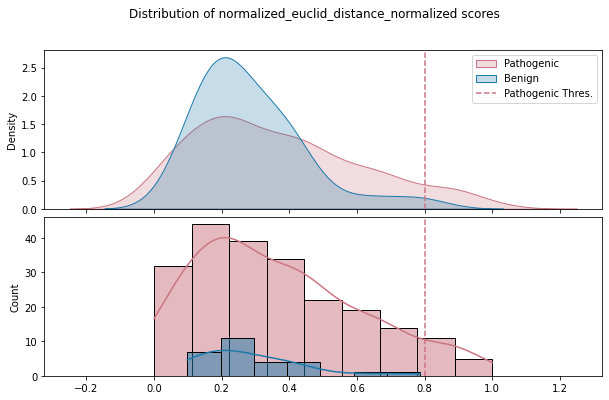

Benign: 0 (0.00%)
Pathogenic: 16 (7.27%)
VUS: 4 (4.44%)
Conflicting: 5 (6.85%)


In [413]:
plot_patho_benign(scores=orf_distances_ben, threshold=True)

In [414]:
orf_distances

db_orf_id,db_mut_id,euclid_distance,log2fc_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,cosine_distance,mean_log2fc,median_log2fc,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,ppi_hit
i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64
2713,838,0.869509,3.499453,0.474191,0.063212,0.474191,2.965919,2.965919,1.568479,1.568479,null,4.584122,0.038659,-0.793622,-0.801215,15,false,0.266667,-0.193696,-0.396671,0.191365,0.144815,0.337164,false,false,0.449457,false,false,0.266667,0.224506,1.183615,0.283046,"""MLH1""","""Ser508Arg""","""1524T>G""","""ENSG00000076242""","""Edgotyping3""","""4_VUS""",0.000001,2.0,"""MLH1_Ser508Arg""",0
9866,216928,0.286929,2.93159,0.230084,-0.733341,0.230084,4.690973,4.690973,2.229887,2.229887,null,2.620482,0.006155,-2.067801,-2.067801,2,true,1.0,-0.200759,-0.760083,0.037818,0.062337,0.213175,false,false,0.263096,true,false,1.0,0.20289,1.85296,0.255793,"""ZMYND10""","""Leu266Pro""","""797T>C""","""ENSG00000004838""","""CEGS2""","""1_Pathogenic""",null,1.0,"""ZMYND10_Leu266Pro""",0
2920,214437,0.305822,1.145988,-0.036816,0.862553,0.036816,0.917939,0.917939,-0.12353,0.12353,null,1.770064,0.021511,0.480726,0.450942,4,false,0.0,0.127432,0.428569,0.358998,0.319113,1.089397,true,false,0.323574,false,true,0.0,0.152911,0.885032,0.192782,"""GFAP""","""Glu371Gly""","""1112A>G""","""ENSG00000131095""","""CEGS2""","""5_Others""",null,null,"""GFAP_Glu371Gly""",0
71892,3998,0.150235,1.420914,0.125878,-0.366033,0.125878,2.396926,2.396926,1.261185,1.261185,null,1.193022,0.007847,-0.959066,-0.959066,2,false,0.5,-0.103943,-0.474416,0.153277,0.058707,0.417201,false,false,0.242307,false,false,0.5,0.106233,0.843594,0.133932,"""TH""","""Thr463Met""","""1388C>T""","""ENSG00000180176""","""Edgotyping3""","""3_Conflicting""",null,1.0,"""TH_Thr463Met""",0
11805,2123,0.457169,3.583087,0.405514,-0.703171,0.405514,8.74495,8.74495,3.12845,3.12845,null,2.139727,0.103604,-2.4395,-2.4395,2,true,1.0,-0.308306,-0.79441,0.129031,0.052358,0.114352,false,false,0.37904,true,false,1.0,0.323268,1.513016,0.407559,"""SMAD3""","""Cys109Tyr""","""326G>A""","""ENSG00000166949""","""Edgotyping3""","""4_VUS""",null,1.0,"""SMAD3_Cys109Tyr""",0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
70497,3874,0.31366,1.639306,0.31366,-0.679136,0.31366,3.116586,3.116586,1.639967,1.639967,null,1.423967,0.0,-1.639517,-1.639517,1,true,1.0,-0.31366,-0.679136,null,0.148192,0.320864,false,false,0.461852,true,false,1.0,0.31366,1.423967,0.395447,"""AGXT""","""Ala295Thr""","""883G>A""","""ENSG00000172482""","""Edgotyping3""","""3_Conflicting""",0.003015,1.0,"""AGXT_Ala295Thr""",0
13796,218139,0.0873,0.341635,0.034914,0.143337,0.034914,1.215799,1.215799,0.281905,0.281905,null,0.617833,0.004094,-0.044176,-0.044176,2,false,0.0,0.02255,-0.017079,0.226863,0.161789,0.822504,true,false,0.377464,false,true,0.0,0.06173,0.436874,0.077826,"""HBD""","""Gly26Asp""","""77G>A""","""ENSG00000223609""","""CEGS2""","""5_Others""",null,null,"""HBD_Gly26Asp""",0
3732,201253,0.273213,2.887304,0.273213,-0.865118,0.273213,7.413887,7.413887,2.89023,2.89023,null,2.535135,0.0,-2.889161,-2.889161,1,true,1.0,-0.273213,-0.865118,null,0.042597,0.134882,false,false,0.315811,true,false,1.0,0.273213,2.535135,0.344453,"""UROD""","""Met165Arg""","""494T>G

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_6362/802856055.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_6362/802856055.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others'], rotation=30)


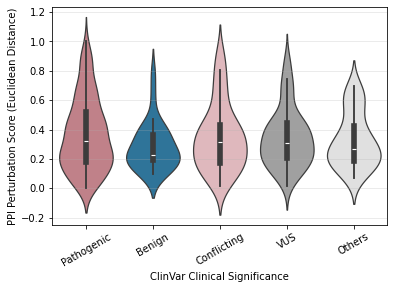

In [416]:
order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS", "5_Others"]

ax = sns.violinplot(
    data=orf_distances_ben,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pillar"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others'], rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()
